<a id="inicio"></a>
# Do texto aos modelos: nosso seminário completo

**Nestor, Letícia e Gabriel · MAE5920 · Introdução a Deep Learning**

**Pergunta que guia o trabalho:** como uma sequência de palavras vira uma decisão,
o que o treinamento modifica e o que acontece quando intervimos em uma ativação?

Este é o roteiro único para o grupo. Ele reúne dados, tokenização, código da CNN,
treino, hiperparâmetros, BPE, BERT/DistilBERT/ModernBERT, mecanismos do livro e steering
do Qwen. As arquiteturas e o treinador aparecem no próprio notebook.

**Três tipos de evidência, sempre identificados:**

| Tipo | O que acontece ao executar |
|---|---|
| **Exercício em CPU** | Rodamos exemplos pequenos para observar operações, gradientes e testes. Não são novos resultados do IMDb. |
| **Experimento real já executado** | Conferimos curvas e logits preservados, sem treinar de novo os modelos grandes. |
| **Treino completo opcional** | No final há código para repetir as CNNs com o corpus restaurado e diretório novo. Os pesos dos encoders e do Qwen exigem execução separada. |

**Como usar:** leia de cima para baixo. Para apresentar só a linha principal, use
as seções 1–8 e 12. Os mecanismos e o steering são extensões didáticas nas seções 9–11.
Todas as células padrão executam em CPU, sem downloads e sem depender dos módulos do repositório.
Os dados necessários à leitura estão anexados a este próprio arquivo.

Para apenas ler e mostrar ao grupo, abra a versão já executada no GitHub.
Para rodar, baixe o `.ipynb` e abra no Jupyter ou no VS Code. Se usar um serviço
que abre notebooks sem copiá-los para o runtime, copie também o próprio `.ipynb`
para o diretório de arquivos da sessão, pois ele contém seus anexos.

### Roteiro

1. <a href="#dados">Problema e papéis dos dados</a>
2. <a href="#tokens">Limpeza, palavras, vocabulário e padding</a>
3. <a href="#cnn">A CNN no código e nos tensores</a>
4. <a href="#treino">Loss, gradientes e treinamento</a>
5. <a href="#experimentos">Como escolhemos hiperparâmetros</a>
6. <a href="#bpe">BPE aprendido somente no treino</a>
7. <a href="#encoders">BERT, DistilBERT e ModernBERT</a>
8. <a href="#resultados">Métricas, exemplos e o que o modelo usa</a>
9. <a href="#mecanismos">MLPs, resíduos, inicialização e regularização</a>
10. <a href="#double-descent">Double descent em regressão sintética</a>
11. <a href="#qwen">Qwen: classificação e intervenção nas ativações</a>
12. <a href="#originais">O experimento original e os limites da comparação</a>
13. <a href="#testes">Testes e auditoria dos resultados</a>
14. <a href="#reproduzir">Repetir o treino completo das CNNs</a>
15. <a href="#referencias">Referências e roteiro da fala</a>

**Ambiente:** Python 3.11 ou posterior, NumPy, pandas, SciPy, scikit-learn,
Matplotlib, PyTorch, Tokenizers e IPython. Se necessário, instale em uma célula
própria: `%pip install numpy pandas scipy scikit-learn matplotlib torch 'tokenizers>=0.22,<0.23'`.
As células de treino completo dos encoders, definidas mas não chamadas, usam Transformers 4.57.x.

In [1]:
# Dependências comuns. Não há import de imdb_lab nem download de modelos.
from pathlib import Path, PurePosixPath
from dataclasses import dataclass
from collections import Counter
from contextlib import nullcontext, redirect_stdout
from types import SimpleNamespace
import base64, copy, hashlib, html, io, json, math, re, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from scipy.linalg import svd
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score
from tokenizers import Tokenizer, models, pre_tokenizers, trainers, decoders
from IPython.display import display, HTML, Image

torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"font.size": 10, "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .15, "figure.dpi": 110})
pd.set_option("display.max_colwidth", 110)
CORES = ["#167D92", "#DF8B2F", "#7957A0", "#CE5351"]
CHECKS = []
def conferir(nome, condicao):
    assert bool(condicao), nome
    CHECKS.append(nome)

# O anexo fica no próprio .ipynb, evitando um bloco enorme de base64 no código visível.
# Se renomear o arquivo, o identificador na metadata também permite encontrá-lo.
candidatos = [Path("seminario_completo.ipynb"), Path("notebooks/seminario_completo.ipynb")]
candidatos += list(Path.cwd().glob("*.ipynb"))
arquivo_notebook = None
for candidato in dict.fromkeys(candidatos):
    if candidato.is_file():
        documento = json.loads(candidato.read_text())
        if documento.get("metadata", {}).get("mae5920_seminar", {}).get("format") == 1:
            arquivo_notebook = candidato
            break
if arquivo_notebook is None:
    raise FileNotFoundError("Mantenha este .ipynb no diretório de execução ou em notebooks/.")
meta = documento["metadata"]["mae5920_seminar"]
pacote = base64.b64decode(documento["cells"][0]["attachments"]["evidencias.zip"]["application/zip"])
conferir("Anexo íntegro", hashlib.sha256(pacote).hexdigest() == meta["payload_sha256"])
ARQUIVOS = zipfile.ZipFile(io.BytesIO(pacote))
for nome, registro in meta["assets"].items():
    if nome.startswith("source_archive/"): continue
    conferir("Hash: " + nome, hashlib.sha256(ARQUIVOS.read(nome)).hexdigest() == registro["sha256"])
def read_json(nome): return json.loads(ARQUIVOS.read(meta["aliases"].get(str(nome),str(nome))))
def read_npz(nome): return np.load(io.BytesIO(ARQUIVOS.read(str(nome))), allow_pickle=False)
def read_csv(nome): return pd.read_csv(io.BytesIO(ARQUIVOS.read(str(nome))))
def figura(nome): display(Image(data=ARQUIVOS.read(nome)))
seq = read_json("results/sequences/presentation_data.json")
s = seq["summary"]
bp = read_json("results/bpe/summary.json")
cfg = read_json("sequence_config.json")
SROOT = PurePosixPath("results/sequences")
def settings(): return cfg
print("Pronto: evidências incorporadas, CPU e nenhuma conexão de rede necessária.")

Pronto: evidências incorporadas, CPU e nenhuma conexão de rede necessária.


<a id="dados"></a>
## 1. O problema e os papéis dos dados

IMDb tem resenhas em inglês e rótulos binários: **0 = negative**, **1 = positive**.
O objetivo é estimar a opinião sobre o filme. Uma probabilidade perto de 0,5 indica
incerteza deste classificador, não uma classe neutra que exista na base.

Na preparação original, limpamos HTML, identificamos textos duplicados e separamos
treino, validação e calibração. O teste oficial tem 25 mil resenhas. Nas extensões,
usamos apenas o treino oficial limpo, sem reabrir o teste oficial.

| Papel | Pode modificar o quê? |
|---|---|
| Treino | Vocabulário, BPE, estatísticas de entrada e pesos da rede |
| Validação | Escolha de taxa e época entre opções já previstas |
| Auditoria interna | Só mede os checkpoints congelados |
| Calibração original | Ajusta temperatura depois da seleção do modelo |

Há **três auditorias internas diferentes**: MLP, CNN/encoders e BPE. Treino e
validação das extensões sequenciais são os mesmos. Cada nova auditoria excluiu
os papéis dos estudos didáticos anteriores. Não colocamos números de auditorias
diferentes numa única competição. Elas são novas para os checkpoints específicos
da extensão; os modelos originais já viram um treino oficial mais amplo.

In [2]:
manifestos = {nome: read_json(f"results/{nome}/data_manifest.json")
              for nome in ["didactic", "sequences", "bpe"]}
display(pd.DataFrame([
    {"estudo": nome, "papel": papel, "n": dados["n"],
     "negativos": dados["label_counts"]["0"], "positivos": dados["label_counts"]["1"]}
    for nome, m in manifestos.items() for papel, dados in m["roles"].items()
]))
for nome, m in manifestos.items():
    for a, aa in m["roles"].items():
        for b, bb in m["roles"].items():
            if a != b: conferir(f"Papéis disjuntos: {nome}/{a}/{b}", set(aa["ids"]).isdisjoint(bb["ids"]))
anteriores = set().union(*(set(r["ids"]) for n in ["didactic", "sequences"]
                           for r in manifestos[n]["roles"].values()))
conferir("Auditoria BPE exclui todos os papéis didáticos anteriores",
         set(manifestos["bpe"]["roles"]["audit"]["ids"]).isdisjoint(anteriores))
print("Teste oficial preservado nas extensões. Treino/validação sequenciais: 6.144 / 1.536.")

,estudo,papel,n,negativos,positivos
0,didactic,train,6144,3072,3072
1,didactic,validation,1536,768,768
2,didactic,audit,2048,1024,1024
3,sequences,train,6144,3072,3072
4,sequences,validation,1536,768,768
5,sequences,audit,2048,1024,1024
6,bpe,train,6144,3072,3072
7,bpe,validation,1536,768,768
8,bpe,audit,2048,1024,1024


Teste oficial preservado nas extensões. Treino/validação sequenciais: 6.144 / 1.536.


<a id="tokens"></a>
## 2. Como o texto se torna uma sequência de índices

**O código abaixo é extraído da implementação usada nos experimentos.**
Primeiro removemos HTML e normalizamos espaços. Nas extensões CNN/encoders e BPE,
guardamos o prefixo de até 128 palavras separadas por espaço. Depois aplicamos o
tokenizer específico de cada modelo, com limite de 256 tokens nas redes sequenciais.

Na CNN por palavras, a expressão regular conserva letras, números e uma contração
com apóstrofo reto. Convertemos para minúsculas. Não fazemos stemming, lematização
ou remoção de stop words. A pontuação desaparece. `wasn't` fica inteiro, `well-made`
vira duas palavras e `10/10` vira dois números. Apóstrofos curvos não são normalizados
para o apóstrofo reto: veja o exemplo.

In [3]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.I)
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

TOKEN_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+", re.I)

def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())


@dataclass
class Vocabulary:
    token_to_id: dict

    @classmethod
    def fit(cls, texts, max_tokens=20000):
        counts = Counter()
        for text in texts:
            counts.update(tokenize(text))
        # Sorting ties makes the vocabulary independent of Counter internals.
        words = sorted(counts, key=lambda w: (-counts[w], w))[:max_tokens - 2]
        return cls({"<pad>": 0, "<unk>": 1, **{w: i + 2 for i, w in enumerate(words)}})

    def encode(self, text, max_length):
        return [self.token_to_id.get(t, 1) for t in tokenize(text)[:max_length]] or [1]

In [4]:
bruto = "<p>The WELL-made movie wasn't good!</p><br>Rating: 10/10. Don’t ignore it."
limpo = clean_text(bruto)
prefixo = " ".join(limpo.split()[:128])
print("Original:", bruto)
print("Limpo:", limpo)
print("Tokens:", tokenize(prefixo))
vocab_corpus = Vocabulary(read_json("results/sequences/vocabulary.json"))
display(pd.DataFrame({"token": tokenize(prefixo), "índice": vocab_corpus.encode(prefixo, 256)}))
# Uma aprendizagem mínima, separada da base real, para enxergar o efeito do fit.
vocab_aula = Vocabulary.fit(["good acting", "warm acting", "bad movie"], max_tokens=20)
conferir("Palavra do holdout não entra no vocabulário de treino", vocab_aula.encode("unseenword", 10) == [1])
conferir("Contração com apóstrofo reto preservada", tokenize("wasn't") == ["wasn't"])
conferir("Hífen e barra são fronteiras", tokenize("well-made 10/10") == ["well", "made", "10", "10"])
display(vocab_aula.token_to_id)

Original: <p>The WELL-made movie wasn't good!</p><br>Rating: 10/10. Don’t ignore it.
Limpo: The WELL-made movie wasn't good! Rating: 10/10. Don’t ignore it.
Tokens: ['the', 'well', 'made', 'movie', "wasn't", 'good', 'rating', '10', '10', 'don', 't', 'ignore', 'it']


,token,índice
0,the,2
1,well,69
2,made,78
3,movie,14
4,wasn't,253
5,good,43
6,rating,646
7,10,192
8,10,192
9,don,1765


{'<pad>': 0,
 '<unk>': 1,
 'acting': 2,
 'bad': 3,
 'good': 4,
 'movie': 5,
 'warm': 6}

### Vocabulário, embedding e padding são objetos diferentes

O vocabulário guarda as 19.998 palavras mais frequentes do **treino** e dois tokens
especiais: `<pad>` = 0 e `<unk>` = 1. Empates são resolvidos alfabeticamente.
O índice é uma chave, sem noção de distância entre palavras.

O **embedding** transforma esse índice em 128 números aprendidos por gradiente.
Portanto, montar o vocabulário não treina os vetores. Para formar um lote, completamos
as sequências com zeros e carregamos também seu comprimento real. Uma entrada vazia
recebe UNK. Comprimentos e máscaras evitam que janelas de padding vençam o máximo.

In [5]:
def empacotar(textos, vocab, cap=256, target="cpu"):
    sequencias = [vocab.encode(t, cap) for t in textos]
    comprimentos = torch.tensor([len(x) for x in sequencias], device=target)
    largura = max(5, max(map(len, sequencias)))
    ids = torch.zeros((len(sequencias), largura), dtype=torch.long, device=target)
    for i, x in enumerate(sequencias): ids[i, :len(x)] = torch.tensor(x, device=target)
    return {"input_ids": ids, "lengths": comprimentos}

frases = ["The movie wasn't good", "Good acting", ""]
lote = empacotar(frases, vocab_corpus)
print("Índices: "); display(lote["input_ids"])
print("Comprimentos reais:", lote["lengths"].tolist())
conferir("Entrada vazia tem uma unidade UNK", lote["input_ids"][2, 0].item() == 1 and lote["lengths"][2].item() == 1)

Índices: 


tensor([[  2,  14, 253,  43,   0],
        [ 43,  97,   0,   0,   0],
        [  1,   0,   0,   0,   0]])

Comprimentos reais: [4, 2, 1]


### Um baseline antes da rede: TF-IDF e regressão logística

O baseline representa frequências de palavras e pares de palavras, ponderadas
pelo IDF aprendido no treino, e ajusta uma fronteira linear. Serve para perguntar
quanto já conseguimos com uma representação simples. Ele não é uma rede profunda.
O vocabulário TF-IDF usa outra regra de tokenização da biblioteca; manter o texto
de entrada comum não torna as representações idênticas.

A função abaixo reproduz a receita da comparação sequencial: no máximo 20 mil
features, `min_df=2`, unigramas/bigramas, TF sublinear e três valores de C.
Ela será executada adiante nas mesmas frases próprias do exercício em CPU.

In [6]:
def ajustar_baseline(textos_treino, y_treino, textos_validacao, y_validacao):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    bc=cfg["baseline"]
    vetorizar=TfidfVectorizer(max_features=bc["max_features"],min_df=bc["min_df"],
                              ngram_range=tuple(bc["ngram_range"]),sublinear_tf=True)
    tx=vetorizar.fit_transform(textos_treino)  # fit somente no treino
    vx=vetorizar.transform(textos_validacao)
    candidatos=[]
    for c in bc["c_grid"]:
        clf=LogisticRegression(C=c,max_iter=1000,solver="liblinear",random_state=17).fit(tx,y_treino)
        z=clf.decision_function(vx)
        ce=float(np.logaddexp(0,z).mean()-np.mean(np.asarray(y_validacao)*z))
        candidatos.append((ce,c,clf))
    ce,c,clf=min(candidatos,key=lambda item:item[:2])
    return vetorizar,clf,{"C escolhido":c,"CE validação":ce,"features":len(vetorizar.vocabulary_)}

<a id="cnn"></a>
## 3. A arquitetura exata da TextCNN

**Embedding treinável → Conv1D + ReLU → máximo global → concatenação → dropout → Linear.**
A entrada é texto, mas a convolução atua no eixo das posições. Cada filtro vê todos
os 128 canais do embedding, com uma janela de 3, 4 ou 5 tokens. Os mesmos pesos
deslizam pelas posições. Cem filtros em cada ramo produzem 300 máximos.

O código desta classe é o mesmo usado nos treinos, incluindo a máscara antes do
máximo. O tamanho mínimo de cinco posições permite processar também textos curtos.
Para um texto menor que o kernel, preservamos uma janela mínima com zeros.

In [7]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, filters=100, kernels=(3, 4, 5), dropout=.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.convs = nn.ModuleList(nn.Conv1d(embedding_dim, filters, k) for k in kernels)
        self.kernels = tuple(kernels)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(filters * len(kernels), 2)

    def forward(self, input_ids, lengths):
        x = self.embedding(input_ids).transpose(1, 2)
        pooled = []
        for conv, k in zip(self.convs, self.kernels):
            features = torch.relu(conv(x))
            # Padded convolution windows must never win max pooling.
            n_valid = (lengths - k + 1).clamp_min(1)
            keep = torch.arange(features.shape[-1], device=features.device)[None, :] < n_valid[:, None]
            features = features.masked_fill(~keep[:, None, :], torch.finfo(features.dtype).min)
            pooled.append(features.max(dim=2).values)
        return self.classifier(self.dropout(torch.cat(pooled, dim=1)))

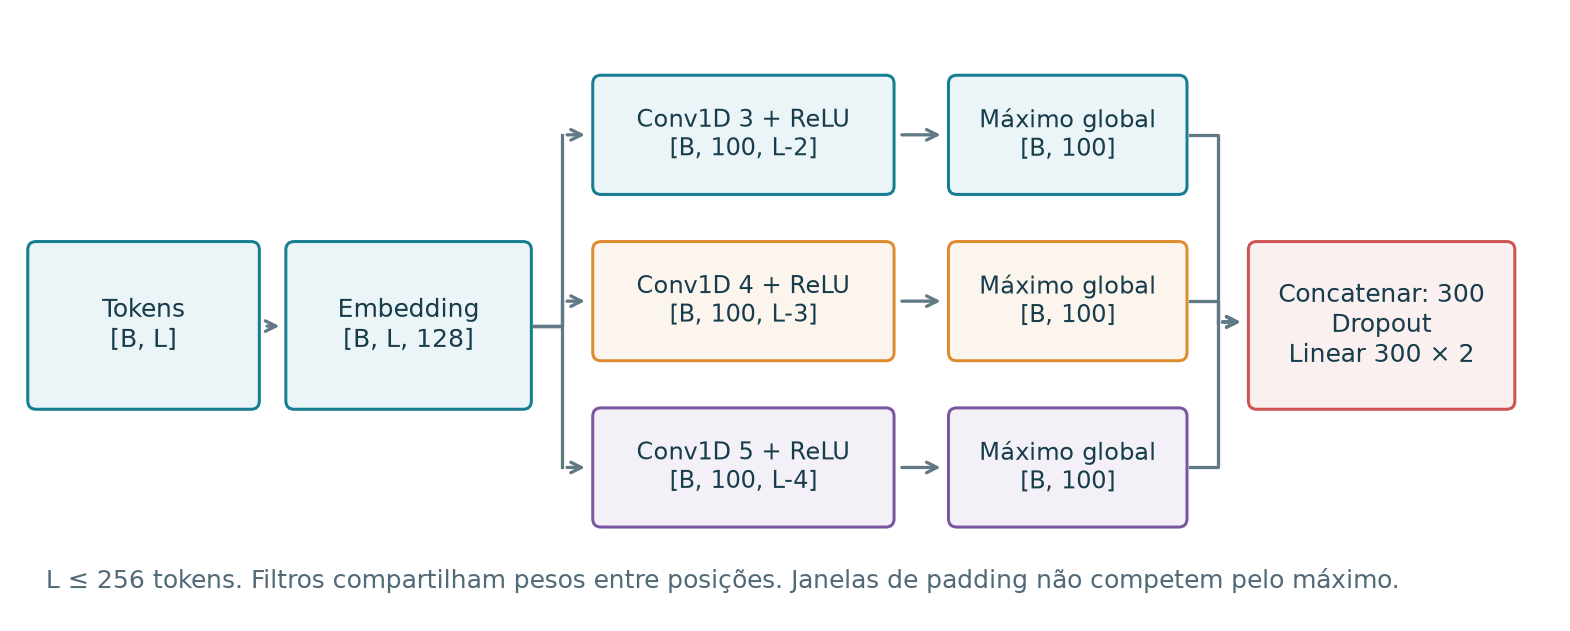

,parâmetro,forma,quantidade,recebe gradiente
0,embedding.weight,"[20000, 128]",2560000,True
1,convs.0.weight,"[100, 128, 3]",38400,True
2,convs.0.bias,[100],100,True
3,convs.1.weight,"[100, 128, 4]",51200,True
4,convs.1.bias,[100],100,True
5,convs.2.weight,"[100, 128, 5]",64000,True
6,convs.2.bias,[100],100,True
7,classifier.weight,"[2, 300]",600,True
8,classifier.bias,[2],2,True


20.000 × 128 + convoluções + saída = 2,714,502 parâmetros registrados.


In [8]:
def initialize_cnn(spec, seed, target):
    torch.manual_seed(seed)
    vocab_n = len(read_json(SROOT / "vocabulary.json"))
    model = TextCNN(vocab_n, spec["embedding_dim"], spec["filters"], spec["kernels"], spec["dropout"])
    nn.init.normal_(model.embedding.weight, std=0.1)
    with torch.no_grad(): model.embedding.weight[0].zero_()
    for conv in model.convs:
        nn.init.kaiming_normal_(conv.weight, nonlinearity="relu"); nn.init.zeros_(conv.bias)
    nn.init.xavier_uniform_(model.classifier.weight); nn.init.zeros_(model.classifier.bias)
    return model.to(target)

modelo = initialize_cnn(cfg["cnn"], seed=17, target=torch.device("cpu"))
figura("results/sequences/figures/cnn_diagram.png")
display(pd.DataFrame([
    {"parâmetro": n, "forma": list(p.shape), "quantidade": p.numel(), "recebe gradiente": p.requires_grad}
    for n, p in modelo.named_parameters()
]))
conta_manual = 20_000 * 128 + sum(100 * (128 * k + 1) for k in [3, 4, 5]) + 2 * (300 + 1)
conferir("Conta analítica da CNN coincide com PyTorch", conta_manual == sum(p.numel() for p in modelo.parameters()) == 2_714_502)
print(f"20.000 × 128 + convoluções + saída = {conta_manual:,} parâmetros registrados.")

### Um forward visto por dentro

A transposição troca `[B, L, 128]` por `[B, 128, L]`, o formato da Conv1D.
Para uma janela de tamanho `k`, a saída tem `L-k+1` posições. O máximo retém
a resposta mais forte de cada filtro e perde sua posição exata.

A célula abaixo executa a CNN **ainda aleatória** para mostrar dimensões e operações.
As probabilidades não são resultados do modelo treinado. Mais adiante lemos
exemplos reais dos checkpoints escolhidos.

In [9]:
modelo.eval()
with torch.no_grad():
    emb = modelo.embedding(lote["input_ids"])
    canais = emb.transpose(1, 2)
    formas = [{"etapa": "embedding", "forma": list(emb.shape)},
              {"etapa": "transposição", "forma": list(canais.shape)}]
    maximos = []
    for conv, k in zip(modelo.convs, modelo.kernels):
        raw = conv(canais)
        ativ = torch.relu(raw)
        validas = (lote["lengths"] - k + 1).clamp_min(1)
        mask = torch.arange(ativ.shape[-1])[None, :] < validas[:, None]
        ativ = ativ.masked_fill(~mask[:, None, :], torch.finfo(ativ.dtype).min)
        maximos.append(ativ.max(2).values)
        formas.append({"etapa": f"Conv{k}, ReLU e pooling", "forma": [list(raw.shape), list(maximos[-1].shape)]})
    vetor = torch.cat(maximos, 1)
    logits = modelo.classifier(vetor)
    torch.testing.assert_close(logits, modelo(**lote))
    # Um escalar da Conv1D, calculado manualmente com os mesmos pesos.
    manual = (canais[0, :, :3] * modelo.convs[0].weight[0]).sum() + modelo.convs[0].bias[0]
    torch.testing.assert_close(manual, modelo.convs[0](canais)[0, 0, 0], atol=1e-6, rtol=1e-6)
conferir("Forward decomposto coincide com a classe", torch.allclose(logits, modelo(**lote), atol=1e-6))
conferir("Convolução manual coincide com a Conv1D", abs(float((manual - modelo.convs[0](canais)[0, 0, 0]).detach())) < 1e-6)
formas.extend([{"etapa": "concatenação", "forma": list(vetor.shape)}, {"etapa": "logits", "forma": list(logits.shape)}])
display(pd.DataFrame(formas))
display(pd.DataFrame(torch.softmax(logits, 1).numpy(), columns=["P(negativo), aleatório", "P(positivo), aleatório"]))

,etapa,forma
0,embedding,"[3, 5, 128]"
1,transposição,"[3, 128, 5]"
2,"Conv3, ReLU e pooling","[[3, 100, 3], [3, 100]]"
3,"Conv4, ReLU e pooling","[[3, 100, 2], [3, 100]]"
4,"Conv5, ReLU e pooling","[[3, 100, 1], [3, 100]]"
5,concatenação,"[3, 300]"
6,logits,"[3, 2]"


,"P(negativo), aleatório","P(positivo), aleatório"
0,0.413259,0.586741
1,0.477739,0.522261
2,0.501496,0.498504


**Teste que importa:** acrescentar padding à direita não pode mudar a predição.
O zero no embedding, sozinho, não basta: o viés de uma convolução pode gerar resposta
numa janela composta de padding. Por isso mascaramos as janelas inválidas antes do máximo.

In [10]:
estendido = {"input_ids": F.pad(lote["input_ids"], (0, 15)), "lengths": lote["lengths"]}
with torch.no_grad():
    conferir("CNN invariante a padding adicional à direita",
             torch.allclose(modelo(**lote), modelo(**estendido), atol=1e-6, rtol=1e-6))
print("Teste passou: a máscara protege o pooling.")

Teste passou: a máscara protege o pooling.


<a id="treino"></a>
## 4. Como treinamos a rede

A rede produz dois **logits**. A entropia cruzada combina log-softmax e a perda
do rótulo correto, com estabilidade numérica. Passamos logits diretamente a
`cross_entropy`; softmax aparece apenas para leitura de probabilidades.

Um minibatch faz: `zero_grad` → `forward` → `loss.backward` → clipping → `step`.
O gradiente aponta a variação local da perda. O otimizador transforma esse
gradiente numa atualização dos parâmetros. No modo treino, dropout fica ativo;
ao medir treino e validação, usamos `eval`, sem dropout e sem gradientes.

In [11]:
# EXERCÍCIO EM CPU, com frases próprias. Este passo não mede desempenho no IMDb.
passo_modelo = initialize_cnn(cfg["cnn"], 17, torch.device("cpu"))
passo_modelo.train()
alvo = torch.tensor([0, 1, 0])
otimizador = torch.optim.Adam(passo_modelo.parameters(), lr=.001)
antes = passo_modelo.convs[0].weight.detach().clone()
otimizador.zero_grad(set_to_none=True)
saida = passo_modelo(**lote)
loss = F.cross_entropy(saida, alvo)
manual_ce = -F.log_softmax(saida, 1)[torch.arange(len(alvo)), alvo].mean()
loss.backward()
gradiente_embedding = passo_modelo.embedding.weight.grad
norma = nn.utils.clip_grad_norm_(passo_modelo.parameters(), 1., error_if_nonfinite=True)
otimizador.step()
conferir("CE recebe logits, fórmula independente confere", torch.allclose(loss, manual_ce))
conferir("PAD não recebe gradiente", torch.count_nonzero(gradiente_embedding[0]).item() == 0)
conferir("Embedding PAD permanece zero", torch.count_nonzero(passo_modelo.embedding.weight[0]).item() == 0)
conferir("Backward e Adam realmente alteram os filtros", not torch.equal(antes, passo_modelo.convs[0].weight))
print({"CE do minibatch": float(loss.detach()), "norma antes do clipping": float(norma),
       "norma da atualização no primeiro kernel": float((antes - passo_modelo.convs[0].weight).norm().detach())})

{'CE do minibatch': 0.6732462048530579, 'norma antes do clipping': 1.5572103261947632, 'norma da atualização no primeiro kernel': 0.13615739345550537}


### O laço usado na comparação sequencial

Estas funções vêm da mesma implementação que treinou CNNs e encoders. O treinador
recebe **somente treino e validação**. Não recebe auditoria. A época zero é um
diagnóstico da rede aleatória. A seleção considera apenas as épocas treinadas.

Para facilitar a leitura, primeiro declaramos as operações auxiliares. Na CNN,
`mixed=False`: FP32 e TF32 desligado na execução GPU original. Os encoders usam
BF16 no autocast, com parâmetros e estados do otimizador em FP32.

In [12]:
def array_hash(x):
    return hashlib.sha256(np.ascontiguousarray(x).tobytes()).hexdigest()


def state_hash(model):
    h = hashlib.sha256()
    for key, value in sorted(model.state_dict().items()):
        h.update(key.encode()); h.update(value.detach().cpu().float().contiguous().numpy().tobytes())
    return h.hexdigest()


def snapshot(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def sync(target):
    if target.type == "cuda": torch.cuda.synchronize()


def autocast(target, enabled):
    return torch.autocast("cuda", dtype=torch.bfloat16) if enabled and target.type == "cuda" else nullcontext()


def orders(n, epochs, seed):
    return [np.random.default_rng(seed + 1009 * e).permutation(n) for e in range(epochs)]


def batches(order, size):
    return [order[i:i + size] for i in range(0, len(order), size)]


def indexed(inputs, indices):
    return {k: v[indices] for k, v in inputs.items()}


def optimizer_for(model, name, lr):
    if name == "adam": return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=0)
    if name == "adamw":
        # Exclude biases and normalization parameters from decoupled decay.
        decay, no_decay = [], []
        for key, p in model.named_parameters():
            (no_decay if p.ndim <= 1 or key.endswith(".bias") else decay).append(p)
        return torch.optim.AdamW([{"params": decay, "weight_decay": settings()["encoders"]["full"]["weight_decay"]},
                                 {"params": no_decay, "weight_decay": 0.0}], lr=lr)
    return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9 if name == "momentum" else 0.0, weight_decay=0)


@torch.inference_mode()
def predict(model, inputs, labels, batch_size, target, mixed=False, features=False):
    model.eval(); outputs = []
    n = len(labels)
    for indices in batches(np.arange(n), batch_size):
        with autocast(target, mixed):
            part = indexed(inputs, indices)
            z = model.features(**part) if features else model(**part)
        outputs.append(z.float().cpu())
    z = torch.cat(outputs)
    if features: return z.numpy()
    y = labels.cpu()
    return {"ce": float(F.cross_entropy(z, y)), "accuracy": float((z.argmax(1) == y).float().mean()), "logits": z.numpy()}

In [13]:
def train_one(model, train, validation, spec, seed, target):
    """Shared trainer; no audit argument, no patience-based budget changes."""
    torch.manual_seed(seed + 40000)  # Paired dropout stream, independent of parameter construction.
    tx, ty = train; vx, vy = validation
    initial = state_hash(model); initial_head = state_hash(model.classifier)
    sequence = orders(len(ty), spec["epochs"], seed)
    opt = optimizer_for(model, spec["optimizer"], spec["lr"])
    updates = spec["epochs"] * math.ceil(len(ty) / spec["batch_size"])
    warmup = max(1, round(updates * spec.get("warmup_fraction", 0))) if spec.get("warmup_fraction") else 0
    scheduler = None
    if warmup:
        scheduler = torch.optim.lr_scheduler.LambdaLR(opt, lambda k: k / warmup if k < warmup else max(0.0, (updates - k) / max(1, updates - warmup)))
    batch_eval = spec.get("eval_batch_size", 64)
    history, best_loss, best_epoch, best_state, best_predictions = [], math.inf, None, None, None
    started = time.perf_counter(); train_seconds = 0.0; completed_updates = 0
    if target.type == "cuda": torch.cuda.reset_peak_memory_stats()
    for epoch in range(spec["epochs"] + 1):
        if epoch:
            model.train(); sync(target); tick = time.perf_counter(); summed = 0.0; seen = 0
            for step, indices in enumerate(batches(sequence[epoch - 1], spec["batch_size"])):
                opt.zero_grad(set_to_none=True)
                with autocast(target, spec.get("mixed", False)):
                    logits = model(**indexed(tx, indices)); loss = F.cross_entropy(logits.float(), ty[indices])
                if not bool(torch.isfinite(loss)): raise FloatingPointError(f"Nonfinite loss: {spec}, epoch={epoch}, step={step}")
                loss.backward()
                if spec.get("gradient_clip_norm"):
                    norm = nn.utils.clip_grad_norm_(model.parameters(), spec["gradient_clip_norm"], error_if_nonfinite=True)
                opt.step()
                if scheduler: scheduler.step()
                summed += float(loss.detach().cpu()) * len(indices); seen += len(indices); completed_updates += 1
            sync(target); train_seconds += time.perf_counter() - tick
        tm = predict(model, tx, ty, batch_eval, target, spec.get("mixed", False))
        vm = predict(model, vx, vy, batch_eval, target, spec.get("mixed", False))
        row = {"epoch": epoch, "updates": completed_updates, "train_ce": tm["ce"], "train_accuracy": tm["accuracy"],
               "validation_ce": vm["ce"], "validation_accuracy": vm["accuracy"], "training_seconds": train_seconds,
               "learning_rate": opt.param_groups[0]["lr"]}
        if epoch: row["online_training_ce"] = summed / seen
        history.append(row)
        # The untrained epoch zero is diagnostic only, never a selected checkpoint.
        if epoch and vm["ce"] < best_loss:
            best_loss, best_epoch, best_state = vm["ce"], epoch, snapshot(model)
            best_predictions = {"train": tm["logits"], "validation": vm["logits"]}
        print("EPOCH", spec["run_id"], seed, row, flush=True)
    return {"history": history, "seed": seed, "spec": spec, "initial_state_sha256": initial,
            "initial_head_sha256": initial_head,
            "batch_order_sha256": array_hash(np.concatenate(sequence)), "best_epoch": best_epoch, "best_validation_ce": best_loss,
            "training_seconds": train_seconds, "total_seconds": time.perf_counter() - started,
            "parameters": sum(p.numel() for p in model.parameters()), "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "peak_cuda_allocated_bytes": int(torch.cuda.max_memory_allocated()) if target.type == "cuda" else None,
            "best_state": best_state, "best_predictions": best_predictions}

**Como ler a função:** `model.train()` liga dropout; o bloco de minibatches calcula
e aplica gradientes; `predict` muda para avaliação; o `if` final guarda uma cópia
dos pesos e dos logits quando a CE de validação melhora. O treino continua até
a época 12 para mostrar overfitting, mas o resultado final usa o checkpoint escolhido.

Executaremos o laço com oito frases de treino e quatro de validação, todas próprias.
O vocabulário usado aqui é o já congelado do corpus: não o reajustamos com essas
frases. Essa execução serve para testar o fluxo, não para estimar generalização.

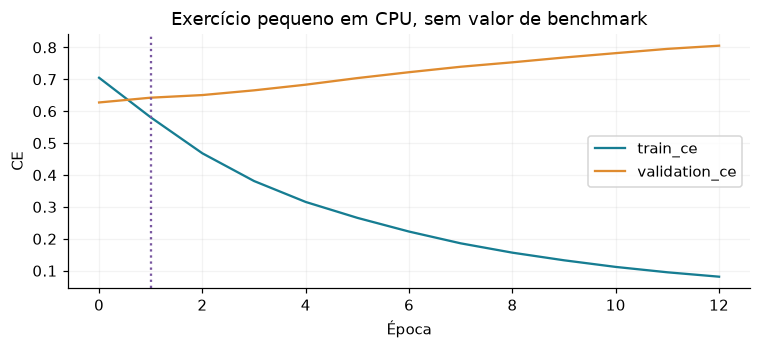

,epoch,updates,train_ce,validation_ce,validation_accuracy
0,0,0,0.7048,0.6273,0.75
1,1,2,0.5806,0.6423,0.75
2,2,4,0.4679,0.6505,0.50
3,3,6,0.3811,0.6653,0.75
4,4,8,0.3155,0.6831,0.75
5,5,10,0.2657,0.7038,0.50
6,6,12,0.2227,0.7222,0.50
7,7,14,0.1858,0.7393,0.50
8,8,16,0.1566,0.7531,0.50
9,9,18,0.1327,0.7682,0.50


Época escolhida: 1 | parâmetros: 2714502
Baseline no mesmo exercício pequeno, sem valor de benchmark: {'C escolhido': 0.5, 'CE validação': 0.6992395543493134, 'features': 21}


In [14]:
aula_treino = [
    ("A warm film with good acting and a moving ending", 1),
    ("The story is engaging and the actors are excellent", 1),
    ("I loved the clever script and the beautiful music", 1),
    ("This wonderful movie is worth watching again", 1),
    ("A dull movie with bad acting and a weak ending", 0),
    ("The story is boring and the actors are terrible", 0),
    ("I hated the empty script and the annoying music", 0),
    ("This awful movie is a waste of time", 0),
]
aula_validacao = [
    ("An enjoyable movie with a lovely story", 1), ("The acting is great and the ending works", 1),
    ("A disappointing film with a boring story", 0), ("The acting is weak and the ending fails", 0),
]
treino_aula = (empacotar([t for t,y in aula_treino], vocab_corpus), torch.tensor([y for t,y in aula_treino]))
validacao_aula = (empacotar([t for t,y in aula_validacao], vocab_corpus), torch.tensor([y for t,y in aula_validacao]))
receita_aula = {**cfg["cnn"], "run_id": "exercicio_cpu", "optimizer": "adam", "lr": .001, "batch_size": 4}
demo = initialize_cnn(cfg["cnn"], 17, torch.device("cpu"))
with redirect_stdout(io.StringIO()):
    ensaio = train_one(demo, treino_aula, validacao_aula, receita_aula, 17, torch.device("cpu"))
esperado = min(ensaio["history"][1:], key=lambda r: r["validation_ce"])
conferir("Checkpoint da aula escolhido apenas pela validação", ensaio["best_epoch"] == esperado["epoch"])
demo.load_state_dict(ensaio["best_state"])
reconstruido = predict(demo, validacao_aula[0], validacao_aula[1], 64, torch.device("cpu"))
conferir("Checkpoint salvo reproduz os logits da validação da aula",
         np.allclose(reconstruido["logits"], ensaio["best_predictions"]["validation"], atol=1e-6))
traj = pd.DataFrame(ensaio["history"])
ax = traj.plot(x="epoch", y=["train_ce", "validation_ce"], color=CORES[:2], figsize=(8,3))
ax.set(xlabel="Época", ylabel="CE", title="Exercício pequeno em CPU, sem valor de benchmark")
ax.axvline(ensaio["best_epoch"], ls=":", color=CORES[2]); plt.show()
display(traj[["epoch","updates","train_ce","validation_ce","validation_accuracy"]].round(4))
print("Época escolhida:", ensaio["best_epoch"], "| parâmetros:", ensaio["parameters"])
_,_,base_aula=ajustar_baseline([t for t,y in aula_treino],[y for t,y in aula_treino],
                              [t for t,y in aula_validacao],[y for t,y in aula_validacao])
print("Baseline no mesmo exercício pequeno, sem valor de benchmark:",base_aula)

<a id="experimentos"></a>
## 5. O que variamos, o que mantivemos e como escolhemos

Agora saímos das oito frases da aula e lemos os **experimentos reais**.
Uma taxa de aprendizado não tem o mesmo efeito em SGD, momentum e Adam.
Por isso fizemos dois gráficos: taxa comum 0,001 e taxa escolhida entre três
candidatas por método. A escolha usa a **média da CE de validação nas três sementes**,
não a semente mais favorável. Acurácia de auditoria não escolhe taxa ou época.

Na CNN, cada condição tem os mesmos dados, matrizes iniciais e minibatches por semente,
12 épocas e clipping de norma 1. A ordem é embaralhada a cada época com uma semente
determinística. O dropout usa uma sequência aleatória pareada, reiniciada pelo treinador.

,optimizer,lr,sementes,épocas
0,adam,0.0003,"[17, 29, 43]",12
1,adam,0.0010,"[17, 29, 43]",12
2,adam,0.0030,"[17, 29, 43]",12
3,momentum,0.0010,"[17, 29, 43]",12
4,momentum,0.0100,"[17, 29, 43]",12
5,momentum,0.1000,"[17, 29, 43]",12
6,sgd,0.0010,"[17, 29, 43]",12
7,sgd,0.0300,"[17, 29, 43]",12
8,sgd,0.3000,"[17, 29, 43]",12


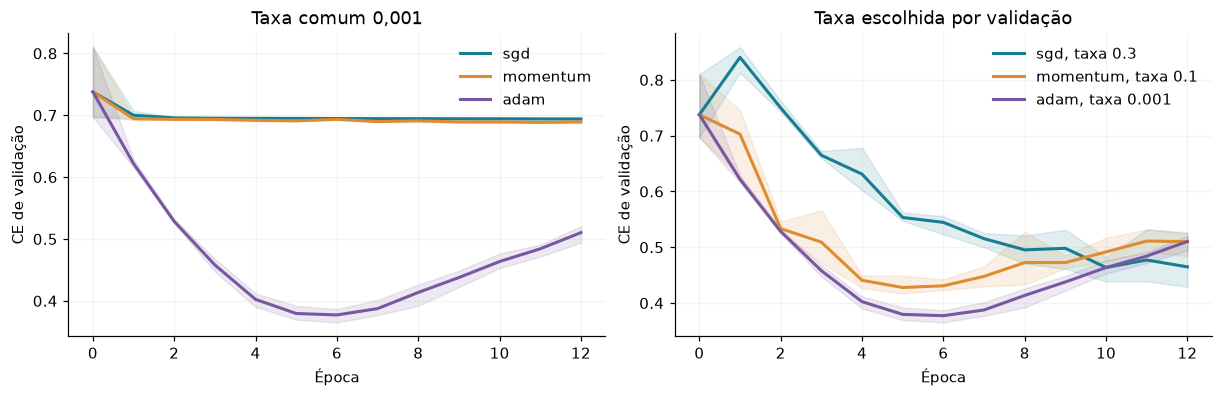

,label,lr,best_epochs,validation_ce_mean,accuracy_mean,ce_mean
0,SGD,0.300,"[12, 12, 10]",0.450508,0.765299,0.479834
1,SGD + momentum,0.100,"[5, 5, 6]",0.425748,0.793457,0.469848
2,Adam,0.001,"[5, 6, 6]",0.376362,0.819499,0.409369


,taxa,CE média da melhor época de cada semente
0,0.0003,0.412708
1,0.0010,0.376362
2,0.0030,0.384419


In [15]:
def select_rate(records):
    rates = sorted({r["spec"]["lr"] for r in records})
    means = {str(lr): float(np.mean([r["best_validation_ce"] for r in records if r["spec"]["lr"] == lr])) for lr in rates}
    return min(rates, key=lambda lr: (means[str(lr)], lr)), means
registros_seq = [read_json(n) for n in ARQUIVOS.namelist()
                 if n.startswith("results/sequences/runs/") and n.endswith(".json")]
curvas_seq = pd.DataFrame([{**h, "run_id": r["run_id"], "seed": r["seed"],
                           "optimizer": r["spec"]["optimizer"], "lr": r["spec"]["lr"],
                           "family": r["spec"]["family"], "group": r["spec"]["group"]}
                          for r in registros_seq for h in r["history"]])
def faixa(ax, linhas, x, y, label, color):
    g = linhas.groupby(x)[y]
    ax.plot(g.mean().index, g.mean().values, color=color, lw=2, label=label)
    ax.fill_between(g.mean().index, g.min().values, g.max().values, color=color, alpha=.13)
def grupo(chave): return next(r for r in s["groups"] if r["key"] == chave)

grade = pd.DataFrame([{k:r["spec"][k] for k in ["optimizer","lr","epochs","batch_size"]} | {"seed":r["seed"]}
                      for r in registros_seq if r["spec"]["family"]=="cnn" and r["spec"]["group"]=="optimizer"])
display(grade.groupby(["optimizer","lr"], as_index=False).agg(sementes=("seed", list), épocas=("epochs","first")))
fig, axes = plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
for i,opt in enumerate(["sgd","momentum","adam"]):
    comum = curvas_seq[(curvas_seq.family=="cnn") & (curvas_seq.group=="optimizer") &
                       (curvas_seq.optimizer==opt) & (curvas_seq.lr==.001)]
    escolhidos = curvas_seq[curvas_seq.run_id.isin(grupo("cnn_"+opt)["run_ids"])]
    faixa(axes[0],comum,"epoch","validation_ce",opt,CORES[i])
    faixa(axes[1],escolhidos,"epoch","validation_ce",f"{opt}, taxa {s['choices']['cnn_'+opt]:g}",CORES[i])
for ax in axes: ax.set(xlabel="Época",ylabel="CE de validação"); ax.legend(frameon=False)
axes[0].set_title("Taxa comum 0,001");axes[1].set_title("Taxa escolhida por validação")
plt.show()
display(pd.DataFrame([grupo("cnn_"+o) for o in ["sgd","momentum","adam"]])[
    ["label","lr","best_epochs","validation_ce_mean","accuracy_mean","ce_mean"]])
candidatos_adam=[r for r in registros_seq if r["spec"]["family"]=="cnn" and r["spec"]["group"]=="optimizer" and r["spec"]["optimizer"]=="adam"]
taxa,medias=select_rate(candidatos_adam)
conferir("Escolha da taxa de Adam reconstruída apenas da validação",taxa==s["choices"]["cnn_adam"])
display(pd.DataFrame([{"taxa":float(t),"CE média da melhor época de cada semente":v} for t,v in medias.items()]))

### Mais filtros, outras janelas e dropout

Testamos janelas 3, 5 e 3/4/5, cem ou 32 filtros por janela, e dropout 0, 0,5 e 0,8.
As variantes reutilizam a taxa escolhida para Adam, sem nova busca por variante.
Reduzir filtros altera só parte da rede: a tabela de parâmetros mostrou que
o embedding ocupa a maior parcela.

**Como interpretar as faixas:** média e mínimo/máximo de três sementes são uma
descrição das partidas escolhidas, não um intervalo de confiança da população.
As curvas de treino são medidas com dropout desligado. Aumentar dropout pode
dificultar o ajuste tanto do treino quanto da validação.

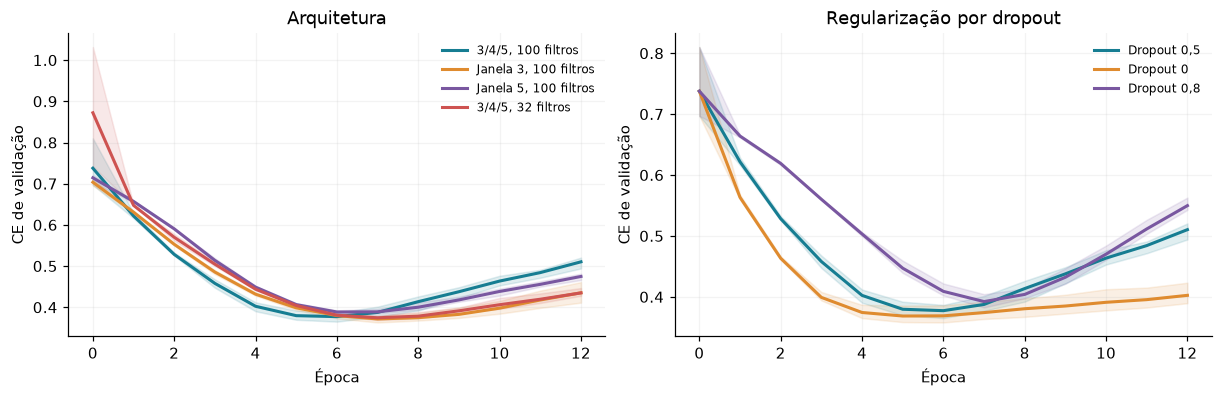

,label,parameters,lr,best_epochs,accuracy_mean,accuracy_min,accuracy_max
0,"3/4/5, 100 filtros",2714502,0.001,"[5, 6, 6]",0.819499,0.817383,0.822754
1,"Janela 3, 100 filtros",2598702,0.001,"[7, 7, 8]",0.812663,0.810059,0.817383
2,"Janela 5, 100 filtros",2624302,0.001,"[7, 6, 6]",0.809408,0.802246,0.816895
3,"3/4/5, 32 filtros",2609442,0.001,"[8, 7, 7]",0.816406,0.812988,0.818359
4,"Dropout 0,5",2714502,0.001,"[5, 6, 6]",0.819499,0.817383,0.822754
5,Dropout 0,2714502,0.001,"[5, 6, 5]",0.818034,0.811523,0.828613
6,"Dropout 0,8",2714502,0.001,"[7, 7, 7]",0.804362,0.801758,0.808105


In [16]:
fig, axes = plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
arquiteturas = [r for r in s["groups"] if r["group"]=="cnn_architecture"]
drops = [r for r in s["groups"] if r["group"]=="cnn_dropout"]
for ax, condicoes in zip(axes,[arquiteturas,drops]):
    for i,r in enumerate(condicoes):
        faixa(ax,curvas_seq[curvas_seq.run_id.isin(r["run_ids"])],"epoch","validation_ce",r["label"],CORES[i])
    ax.set(xlabel="Época",ylabel="CE de validação"); ax.legend(frameon=False,fontsize=8)
axes[0].set_title("Arquitetura");axes[1].set_title("Regularização por dropout");plt.show()
display(pd.DataFrame(arquiteturas+drops)[["label","parameters","lr","best_epochs","accuracy_mean","accuracy_min","accuracy_max"]])
# Conferir pareamento a partir dos metadados realmente preservados.
for seed in cfg["seeds"]:
    parte=[r for r in registros_seq if r["seed"]==seed and r["spec"]["family"]=="cnn" and r["spec"]["group"]=="optimizer"]
    conferir(f"CNN: mesma inicialização entre otimizadores, semente {seed}",len({r["initial_state_sha256"] for r in parte})==1)
    conferir(f"CNN: mesmos minibatches entre otimizadores, semente {seed}",len({r["batch_order_sha256"] for r in parte})==1)

<a id="bpe"></a>
## 6. Aprender BPE no treino muda o quê?

**Palavras:** cada palavra fora do vocabulário vira UNK.
**BPE:** palavras raras podem ser compostas de partes conhecidas.

O BPE começa com caracteres e aprende uniões frequentes. Na nossa implementação,
a limpeza por regex é a mesma da CNN por palavras. `WhitespaceSplit` impede uniões
entre palavras. O marcador `</w>` identifica o final da palavra. Isto é BPE de
caracteres, sem byte fallback, e não o tokenizer do ModernBERT.

Aprendemos o tokenizer nos **6.144 textos de treino, sem usar rótulos** e congelamos
suas regras. Depois treinamos uma nova CNN. O gradiente não altera essas regras:
ele altera embeddings, filtros e saída. Na comparação real, mantivemos 20 mil
entradas e os mesmos 2.714.502 parâmetros, partidas, minibatches e receita de treino.

In [17]:
def canonicalize(text):
    """Hold lexical normalization constant with the original regex tokenizer."""
    return " ".join(tokenize(text))


def fit_bpe(texts, vocab_size=20000, min_frequency=2):
    tokenizer = Tokenizer(models.BPE(unk_token="<unk>", end_of_word_suffix="</w>"))
    tokenizer.pre_tokenizer = pre_tokenizers.WhitespaceSplit()
    tokenizer.decoder = decoders.BPEDecoder(suffix="</w>")
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=min_frequency,
        special_tokens=["<pad>", "<unk>"], end_of_word_suffix="</w>", show_progress=False)
    tokenizer.train_from_iterator((canonicalize(t) for t in texts), trainer, length=len(texts))
    assert tokenizer.token_to_id("<pad>") == 0 and tokenizer.token_to_id("<unk>") == 1
    return tokenizer

In [18]:
def merge_trace(word, tokenizer):
    """Replay the actual learned merge ranks on one canonicalized word."""
    import json
    model = json.loads(tokenizer.to_str())["model"]
    ranks = {tuple(pair): i for i, pair in enumerate(model["merges"])}
    pieces = list(word[:-1]) + [word[-1] + "</w>"]
    rows = [{"step": 0, "rank": None, "pair": None, "tokens": pieces.copy()}]
    while len(pieces) > 1:
        candidates = [(ranks[(a, b)], (a, b)) for a, b in zip(pieces, pieces[1:]) if (a, b) in ranks]
        if not candidates: break
        rank, pair = min(candidates); merged = []; i = 0
        while i < len(pieces):
            if i + 1 < len(pieces) and (pieces[i], pieces[i + 1]) == pair:
                merged.append(pieces[i] + pieces[i + 1]); i += 2
            else: merged.append(pieces[i]); i += 1
        pieces = merged
        rows.append({"step": len(rows), "rank": rank, "pair": list(pair), "tokens": pieces.copy()})
    assert pieces == tokenizer.encode(word).tokens
    return rows

bpe_real = Tokenizer.from_str(ARQUIVOS.read("results/bpe/tokenizer.json").decode())
print("Regras iniciais aprendidas no corpus:", bp["tokenizer_training"]["first_merges"][:6])
display(pd.DataFrame(bp["examples"])[["word","word_tokens","bpe_tokens"]])
trace = merge_trace("pallbearer", bpe_real)
display(pd.DataFrame([{"passo":r["step"], "prioridade aprendida":r["rank"],
                       "peças": " + ".join(r["tokens"])} for r in trace]))
# Aprender outro tokenizer pequeno, apenas para entender a API. Não substitui o real.
bpe_aula = fit_bpe(["low lower lowest new newer newest"]*4, vocab_size=35)
fragmentos = bpe_aula.encode("newestlower")
conferir("BPE da aula compõe palavra nova com alfabeto conhecido", 1 not in fragmentos.ids)
conferir("Decoder reconstitui palavra composta da aula", bpe_aula.decode(fragmentos.ids).strip()=="newestlower")
print("Palavra nunca observada inteira:", fragmentos.tokens)

Regras iniciais aprendidas no corpus: [['t', 'h'], ['i', 'n'], ['th', 'e</w>'], ['a', 'n'], ['e', 'r'], ['i', 's</w>']]


,word,word_tokens,bpe_tokens
0,pallbearer,[<unk>],"[p, all, bearer</w>]"
1,unwatchable,[unwatchable],[unwatchable</w>]
2,wasn't,[wasn't],[wasn't</w>]
3,cinematography,[cinematography],[cinematography</w>]


,passo,prioridade aprendida,peças
0,0,NaN,p + a + l + l + b + e + a + r + e + r</w>
1,1,6.0,p + a + l + l + b + e + a + re + r</w>
2,2,17.0,p + al + l + b + e + a + re + r</w>
3,3,40.0,p + al + l + be + a + re + r</w>
4,4,427.0,p + all + be + a + re + r</w>
5,5,1383.0,p + all + be + are + r</w>
6,6,8537.0,p + all + be + arer</w>
7,7,13882.0,p + all + bearer</w>


Palavra nunca observada inteira: ['ne', 'we', 's', 't', 'lower</w>']


A tabela aplica as prioridades já aprendidas a uma palavra. Não é um novo ajuste
durante a inferência. As peças não precisam corresponder a morfemas. Caracteres
de alfabetos nunca vistos ainda podem gerar UNK.

### Cobertura melhor não implica classificação melhor

Reservamos outra auditoria interna de 2.048 resenhas para os três checkpoints por
palavras e os três BPE. A entrada ficou fora do treino até congelar as escolhas.
A taxa 0,001 veio da CNN por palavras e não foi reajustada para BPE.
Uma janela de três tokens passa a contar subpalavras; seu alcance em palavras muda.

,label,parameters,best_epochs,accuracy_mean,accuracy_min,accuracy_max,ce_mean
0,Palavras,2714502,"[5, 6, 6]",0.819987,0.816406,0.823242,0.396417
1,BPE 20 mil,2714502,"[5, 5, 6]",0.814128,0.812012,0.815430,0.405213


,tokenização,papel,UNK (%),tokens médios,resenhas truncadas
0,bpe,train,0.000000,126.386882,0
1,bpe,validation,0.000000,127.615885,0
2,bpe,audit,0.000000,129.093750,0
3,word,train,1.686362,120.654297,0
4,word,validation,3.205674,119.965495,0
5,word,audit,3.269839,121.299805,0


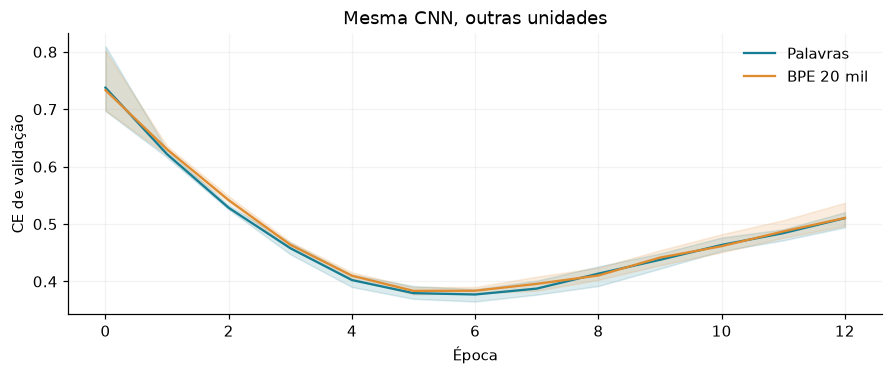

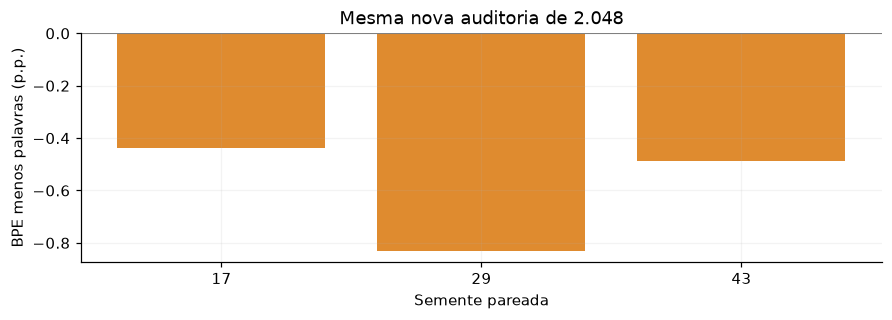

Diferença média: -0.59 p.p. BPE zerou os UNKs observados, sem ganhar acurácia nesta receita.
Reajustar BPE pode gerar regras/IDs diferentes; aqui usamos o JSON exato dos treinos apresentados.


In [19]:
comparacao_bpe = pd.DataFrame(bp["groups"])
display(comparacao_bpe[["label","parameters","best_epochs","accuracy_mean","accuracy_min","accuracy_max","ce_mean"]])
display(pd.DataFrame([{ "tokenização":nome,"papel":papel,"UNK (%)":100*d["unknown_rate"],
                       "tokens médios":d["mean_tokens"],"resenhas truncadas":d["truncated_documents"]}
                     for nome,roles in bp["tokenization"].items() for papel,d in roles.items()]))
fig,ax=plt.subplots(figsize=(8,3.3),constrained_layout=True)
for i,nome in enumerate(["word","bpe"]):
    c=bp["curves"][nome]["validation_ce"]
    ax.plot(c["epochs"],c["mean"],color=CORES[i],label=bp["groups"][i]["label"])
    ax.fill_between(c["epochs"],c["min"],c["max"],color=CORES[i],alpha=.15)
ax.set(xlabel="Época",ylabel="CE de validação",title="Mesma CNN, outras unidades");ax.legend(frameon=False)
plt.show()
fig,ax=plt.subplots(figsize=(8,2.8),constrained_layout=True)
pares=pd.DataFrame(bp["paired_counts"])
ax.bar(pares.seed.astype(str),pares.accuracy_difference_bpe_minus_word_pp,color=CORES[1])
ax.axhline(0,color="gray",lw=.7)
ax.set(xlabel="Semente pareada",ylabel="BPE menos palavras (p.p.)",title="Mesma nova auditoria de 2.048")
plt.show()
print(f"Diferença média: {bp['difference_bpe_minus_word_pp']:.2f} p.p. BPE zerou os UNKs observados, sem ganhar acurácia nesta receita.")
print("Reajustar BPE pode gerar regras/IDs diferentes; aqui usamos o JSON exato dos treinos apresentados.")

<a id="encoders"></a>
## 7. Encoders pré-treinados: o que escrevemos e o que reutilizamos

A CNN aprende tudo do zero. Nos encoders, reutilizamos pesos de pré-treinamento
público, sem ajuste anterior no IMDb, e escrevemos o wrapper de classificação.
**Não reimplementamos os blocos internos de BERT, DistilBERT ou ModernBERT.**
A biblioteca Transformers os carrega; o nosso código faz pooling, dropout e saída.

| Modelo | Tokenização original | Blocos | Vetor por token | Cabeças |
|---|---|---:|---:|---:|
| BERT-base uncased | WordPiece, minúsculas | 12 | 768 | 12 |
| DistilBERT uncased | Mesmo tokenizer WordPiece | 6 | 768 | 12 |
| ModernBERT-base | BPE de bytes, sensível a caixa | 22 | 768 | 12 |

Os tokenizers pré-treinados ficam congelados nos dois regimes. Ajustar o encoder
modifica seus embeddings e blocos, não as regras de segmentação. ModernBERT usa
posições rotativas e atenção local intercalada com global. Não usamos seu contexto
máximo: as entradas desta comparação têm os mesmos prefixos curtos.

,num_hidden_layers,hidden_size,num_attention_heads,parameters
bert,12,768,12,108893186
distilbert,6,768,12,66364418
modernbert,22,768,12,149015810


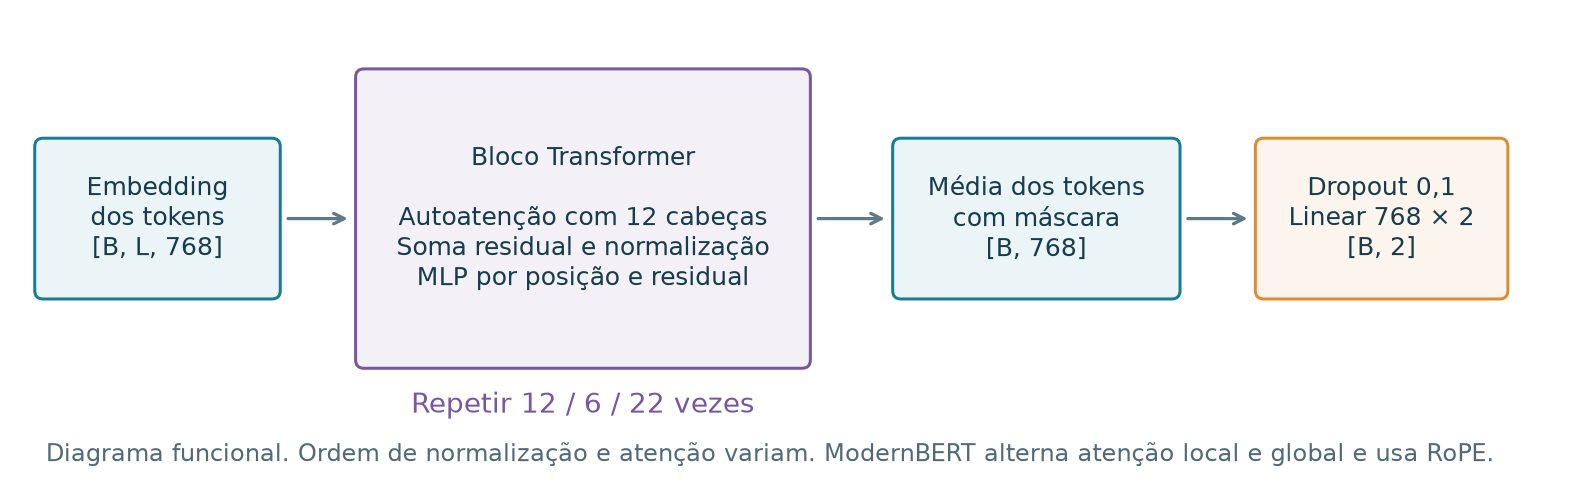

In [20]:
wordpiece = Tokenizer.from_str(ARQUIVOS.read("results/sequences/tokenizers/bert/tokenizer.json").decode())
modern_tokens = Tokenizer.from_str(ARQUIVOS.read("results/sequences/tokenizers/modernbert/tokenizer.json").decode())
# Os arquivos BERT e DistilBERT da execução têm exatamente o mesmo hash.
texto_encoder = "The movie wasn't unwatchable, but the cinematography was underwhelming."
tokenizacoes=[
    {"tokenizador": "CNN por palavras", "tokens": tokenize(texto_encoder)},
    {"tokenizador": "BPE aprendido no nosso treino", "tokens": bpe_real.encode(canonicalize(texto_encoder)).tokens},
    {"tokenizador": "BERT e DistilBERT", "tokens": wordpiece.encode(texto_encoder).tokens},
    {"tokenizador": "ModernBERT", "tokens": modern_tokens.encode(texto_encoder).tokens},
]
for linha in tokenizacoes:
    display(HTML("<p><b>"+html.escape(linha["tokenizador"])+"</b><br><code style='white-space:normal'>"+
                 html.escape(" | ".join(linha["tokens"]))+"</code></p>"))
display(pd.DataFrame(s["encoder_architectures"]).T[["num_hidden_layers","hidden_size","num_attention_heads","parameters"]])
figura("results/sequences/figures/encoder_diagram.png")

### A cabeça que colocamos sobre os encoders

Cada token recebe um vetor contextual. Fazemos a **média dos estados finais**, com
máscara para excluir padding e tokens especiais, seguida de dropout 0,1 e
`Linear(768,2)`. Isso dá **768×2 + 2 = 1.538 parâmetros** na cabeça.
No BERT, removemos o pooler original. Não usamos automaticamente o vetor CLS.

In [21]:
def masked_mean(hidden, mask):
    weight = mask.to(hidden.dtype).unsqueeze(-1)
    return (hidden * weight).sum(1) / weight.sum(1).clamp_min(1)


class MeanEncoder(nn.Module):
    def __init__(self, backbone, hidden_size, dropout=0.1):
        super().__init__(); self.backbone = backbone; self.dropout = nn.Dropout(dropout); self.classifier = nn.Linear(hidden_size, 2)

    def features(self, input_ids, attention_mask, pool_mask, **kwargs):
        result = self.backbone(input_ids=input_ids, attention_mask=attention_mask, **kwargs)
        return masked_mean(result.last_hidden_state, pool_mask)

    def forward(self, **inputs):
        return self.classifier(self.dropout(self.features(**inputs)))

In [22]:
hidden_exemplo = torch.tensor([[[100.,100.],[2.,4.],[4.,8.],[200.,200.],[-50.,-50.]]])
mascara_exemplo = torch.tensor([[False,True,True,False,False]])
conferir("Pooling exclui especiais e padding", torch.equal(masked_mean(hidden_exemplo,mascara_exemplo),torch.tensor([[3.,6.]])))
conferir("Cabeça com 768 dimensões tem 1.538 parâmetros",sum(p.numel() for p in nn.Linear(768,2).parameters())==1538)

def carregar_encoder_real(familia, pasta_pesos):
    # Definida para leitura e uso opcional. Não é chamada na execução padrão.
    # pasta_pesos contém a revisão fixada no manifesto, já baixada e conferida.
    from transformers import AutoConfig, AutoModel
    conf=AutoConfig.from_pretrained(pasta_pesos,local_files_only=True)
    if hasattr(conf,"reference_compile"): conf.reference_compile=False
    extras={"add_pooling_layer":False} if conf.model_type=="bert" else {}
    base=AutoModel.from_pretrained(pasta_pesos,config=conf,local_files_only=True,
                                   attn_implementation="sdpa",**extras)
    hidden=getattr(conf,"hidden_size",getattr(conf,"dim",None))
    return MeanEncoder(base,hidden,dropout=.1)

def grupos_adamw(rede, decay=.01):
    # Vieses e parâmetros unidimensionais de normalização não recebem decay.
    com_decay=[];sem_decay=[]
    for nome,p in rede.named_parameters():
        (sem_decay if p.ndim<=1 or nome.endswith(".bias") else com_decay).append(p)
    return [{"params":com_decay,"weight_decay":decay},{"params":sem_decay,"weight_decay":0.}]

### O que significa congelar e fazer ajuste completo?

No modo **congelado**, o encoder fica em `eval`, não recebe gradientes e gera uma
única vez os vetores de treino/validação. Só a cabeça aprende: 40 épocas, Adam,
três taxas candidatas. No **ajuste completo**, o gradiente atravessa também o encoder:
três épocas, AdamW, duas taxas candidatas, warmup de 10% e redução linear.

São duas receitas práticas: otimizador, orçamento e dropout do encoder também mudam.
Assim, a comparação não isola destravar os pesos como única causa de um ganho.
A miniatura abaixo testa **o caminho do gradiente** com um pequeno Transformer
aleatório em CPU. Ela não é BERT e não fornece métricas dos encoders reais.

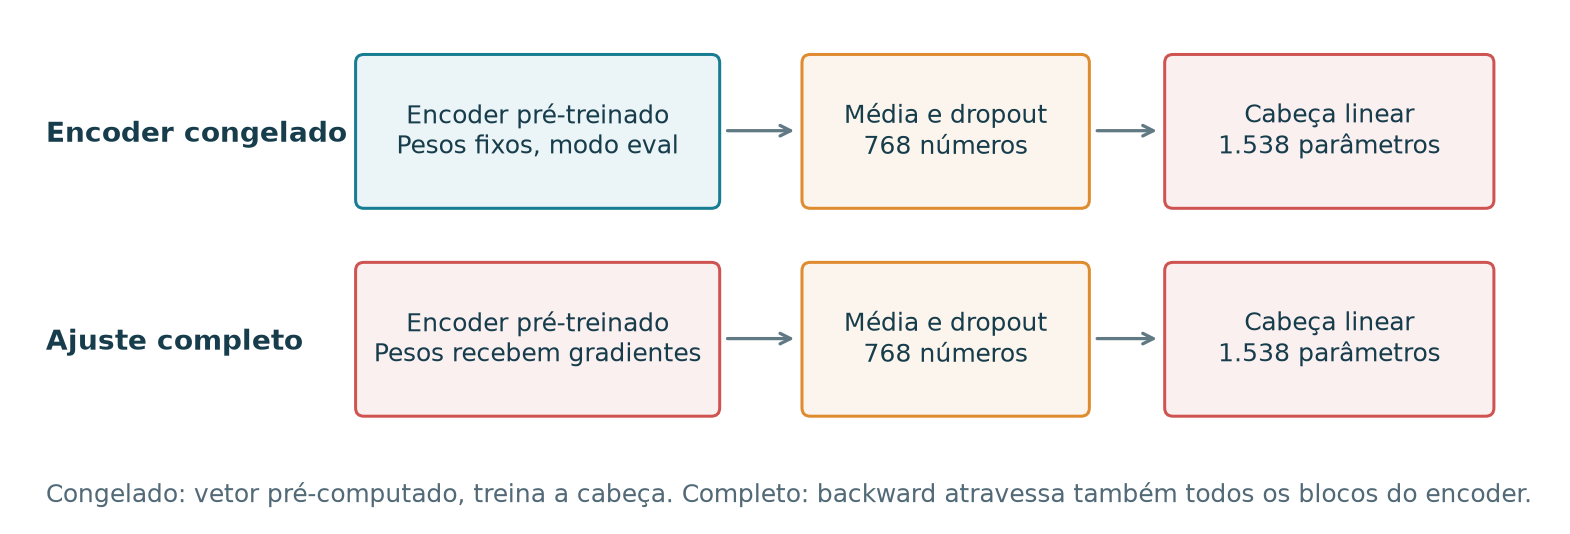

In [23]:
class MiniEncoderAula(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding=nn.Embedding(64,32,padding_idx=0)
        self.posicao=nn.Embedding(16,32)
        bloco=nn.TransformerEncoderLayer(32,4,dim_feedforward=64,dropout=0.,
                                         activation="gelu",batch_first=True)
        self.blocos=nn.TransformerEncoder(bloco,2,enable_nested_tensor=False)
    def forward(self,input_ids,attention_mask):
        pos=torch.arange(input_ids.shape[1])[None,:]
        h=self.embedding(input_ids)+self.posicao(pos)
        h=self.blocos(h,src_key_padding_mask=~attention_mask.bool())
        return SimpleNamespace(last_hidden_state=h)

torch.manual_seed(17)
mini=MeanEncoder(MiniEncoderAula(),32,dropout=.1)
mini_congelado=copy.deepcopy(mini)
mini_congelado.backbone.requires_grad_(False).eval()
mini_congelado.classifier.train()
entrada_mini={"input_ids":torch.tensor([[2,3,4,0],[5,6,7,8]]),
              "attention_mask":torch.tensor([[1,1,1,0],[1,1,1,1]]),
              "pool_mask":torch.tensor([[True,True,True,False],[True,True,True,True]])}
for rede,congelado in [(mini_congelado,True),(mini,False)]:
    rede.zero_grad(set_to_none=True)
    F.cross_entropy(rede(**entrada_mini),torch.tensor([0,1])).backward()
    conferir(f"Cabeça recebe gradiente; congelado={congelado}",rede.classifier.weight.grad is not None)
    tem_grad=any(p.grad is not None for p in rede.backbone.parameters())
    conferir(f"Gradiente atravessa encoder somente no ajuste completo; congelado={congelado}",tem_grad==(not congelado))
figura("results/sequences/figures/transfer_diagram.png")

### Os resultados dos três encoders

As colunas abaixo compartilham a auditoria CNN/encoders, de 2.048 exemplos.
Os checkpoints e as taxas foram fixados por validação antes de liberar essa entrada.
A arquitetura, o pré-treinamento e o vocabulário variam entre famílias; não é um
experimento que mantém todos esses fatores constantes.

,label,parameters,trainable_parameters,lr,best_epochs,accuracy_mean,accuracy_min,accuracy_max,ce_mean
0,BERT-base congelado,108893186,1538,0.01000,"[23, 25, 34]",0.845215,0.844238,0.846191,0.365514
1,BERT-base ajuste completo,108893186,108893186,0.00003,"[2, 1, 1]",0.883138,0.876953,0.886719,0.302736
2,DistilBERT congelado,66364418,1538,0.01000,"[33, 25, 25]",0.833496,0.833008,0.833984,0.383870
3,DistilBERT ajuste completo,66364418,66364418,0.00003,"[1, 2, 2]",0.868001,0.851074,0.877441,0.338196
4,ModernBERT-base congelado,149015810,1538,0.01000,"[21, 21, 36]",0.812988,0.811035,0.815430,0.410333
5,ModernBERT-base ajuste completo,149015810,149015810,0.00003,"[2, 1, 2]",0.912435,0.907227,0.921875,0.245797


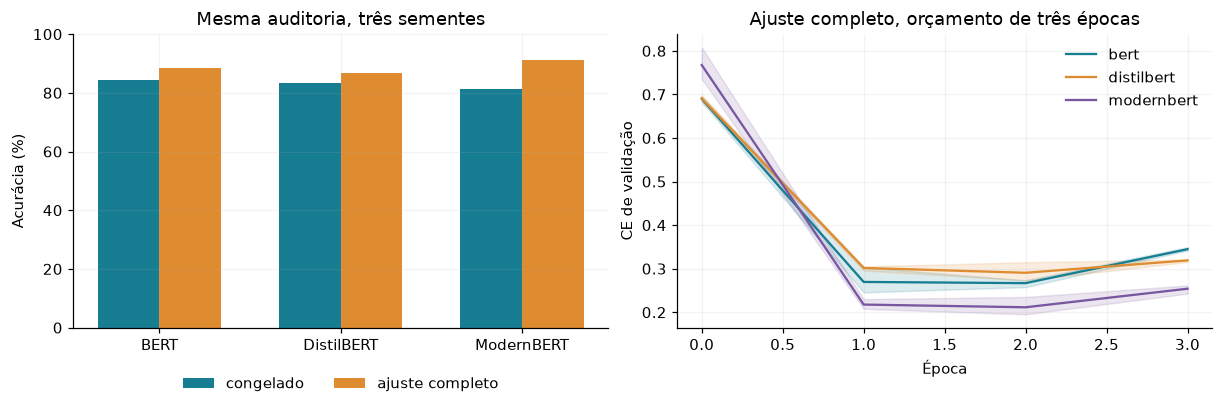

,regime,optimizer,epochs,batch_size,learning_rates,precision
0,probe,Adam,40,128,"[0.001, 0.01, 0.1]",Encoder evaluated once in BF16 autocast; cached features cast to FP32; train only Linear head
1,full,AdamW,3,32,"[1e-05, 3e-05]",BF16 autocast with FP32 weights and optimizer state; CUDA SDPA; TF32 disabled


TF-IDF nesta amostra: 0.8330078125 | CNN + Adam: 0.8194986979166666


In [24]:
enc = pd.DataFrame([r for r in s["groups"] if r["group"]=="encoder"])
display(enc[["label","parameters","trainable_parameters","lr","best_epochs","accuracy_mean","accuracy_min","accuracy_max","ce_mean"]])
fig,axes=plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
nomes=["bert","distilbert","modernbert"]
for j,regime in enumerate(["probe","full"]):
    rr=[grupo(n+"_"+regime) for n in nomes]
    axes[0].bar(np.arange(3)+(j-.5)*.34,[100*r["accuracy_mean"] for r in rr],.34,
                color=CORES[j],label="congelado" if j==0 else "ajuste completo")
axes[0].set(xticks=range(3),xticklabels=["BERT","DistilBERT","ModernBERT"],ylim=(0,100),ylabel="Acurácia (%)",title="Mesma auditoria, três sementes")
axes[0].legend(frameon=False,loc="upper center",bbox_to_anchor=(.5,-.12),ncol=2)
for i,nome in enumerate(nomes):
    c=seq["curves"][nome+"_full"]["validation_ce"]
    axes[1].plot(c["epochs"],c["mean"],label=nome,color=CORES[i])
    axes[1].fill_between(c["epochs"],c["min"],c["max"],color=CORES[i],alpha=.15)
axes[1].set(xlabel="Época",ylabel="CE de validação",title="Ajuste completo, orçamento de três épocas")
axes[1].legend(frameon=False);plt.show()
display(pd.DataFrame([{"regime":nome,**cfg["encoders"][nome]} for nome in ["probe","full"]])[
    ["regime","optimizer","epochs","batch_size","learning_rates","precision"]])
print("TF-IDF nesta amostra:",s["baseline"]["accuracy"],"| CNN + Adam:",grupo("cnn_adam")["accuracy_mean"])

<a id="resultados"></a>
## 8. O mesmo texto nos modelos e a diferença entre métricas

Acurácia conta decisões corretas. F1 macro pondera as duas classes igualmente.
Entropia cruzada penaliza probabilidades atribuídas ao rótulo verdadeiro e pode
piorar quando a rede fica excessivamente confiante. Dois modelos com a mesma
acurácia podem ter perdas muito diferentes.

Os quatro exemplos abaixo foram escritos antes de observar suas predições e
avaliados depois do congelamento, sempre com a semente 17. São textos próprios
sobre negação, reversão de expectativa e avaliação mista. Seus rótulos pretendidos
servem à discussão, não constituem uma nova base de teste.

In [25]:
exemplos=read_json("results/sequences/synthetic_examples.json")["examples"]
for e in exemplos:
    print(e["id"],"| intenção:",e["intended"])
    print(e["text"])
    display(pd.DataFrame([{ "modelo":k,"P(positivo)":p} for k,p in e["probabilities"].items()]))

synthetic_positive | intenção: positivo
The opening is quiet, but the patient storytelling pays off. The actors make the characters believable, the final scene is moving, and the film stays with you after the credits. I would happily watch it again.


,modelo,P(positivo)
0,cnn,0.931260
1,bert_probe,0.991234
2,bert_full,0.997019
3,distilbert_probe,0.997369
4,distilbert_full,0.982823
5,modernbert_probe,0.938089
6,modernbert_full,0.997285
7,tfidf,0.868449


synthetic_negative | intenção: negativo
The premise sounds promising, but the film wastes it. The dialogue is stiff, the characters never develop, and the final twist makes no sense. Even the attractive photography cannot rescue two hours of dull storytelling.


,modelo,P(positivo)
0,cnn,0.085838
1,bert_probe,0.001093
2,bert_full,0.000607
3,distilbert_probe,0.008910
4,distilbert_full,0.016915
5,modernbert_probe,0.003082
6,modernbert_full,0.005220
7,tfidf,0.087738


synthetic_reversal | intenção: positivo
I expected to hate this film. I was wrong. The strange opening leads to a clever story, the cast is excellent, and the ending is surprisingly warm. What looked like a disaster turned out to be a wonderful evening.


,modelo,P(positivo)
0,cnn,0.837535
1,bert_probe,0.546745
2,bert_full,0.975390
3,distilbert_probe,0.591434
4,distilbert_full,0.979511
5,modernbert_probe,0.679141
6,modernbert_full,0.987375
7,tfidf,0.654565


synthetic_mixed | intenção: negativo
Beautiful images, a talented cast, and a memorable score are all here. Unfortunately the story is a mess. The impressive first ten minutes give way to repetitive scenes, empty speeches, and an ending that feels completely unearned. I cannot recommend it.


,modelo,P(positivo)
0,cnn,0.104875
1,bert_probe,0.006555
2,bert_full,0.001988
3,distilbert_probe,0.012242
4,distilbert_full,0.067056
5,modernbert_probe,0.044594
6,modernbert_full,0.038756
7,tfidf,0.322372


### O que a última camada da CNN faz com os máximos dos filtros

Em avaliação, a margem `logit_positivo − logit_negativo` é uma soma exata:
`viés + soma(maximo_do_filtro × diferença_dos_pesos_da_saída)`.
Usamos essa identidade para conferir o cálculo e mostrar janelas que contribuíram
para o sinal. Há 300 parcelas, uma por filtro. A lista curta é só uma ilustração.

**Limite da leitura:** isso descreve a camada final sobre um vetor já calculado.
Não demonstra que remover a palavra causará uma mudança igual à parcela:
a edição altera convoluções, posições e os máximos que chegam à saída.

I expected to hate this film. I was wrong. The strange opening leads to a clever story, the cast is excellent, and the ending is surprisingly warm. What looked like a disaster turned out to be a wonderful evening.
{'margem registrada': 1.640000343322754, 'margem reconstruída': 1.6400004212173371}


,words,kernel,contribution
0,cast is excellent and,4,0.712318
1,cast is excellent,3,0.615091
2,excellent and the ending,4,0.403090
3,the strange opening leads,4,-0.395368
4,disaster turned out to be,5,-0.272999
5,this film i was wrong,5,-0.270409


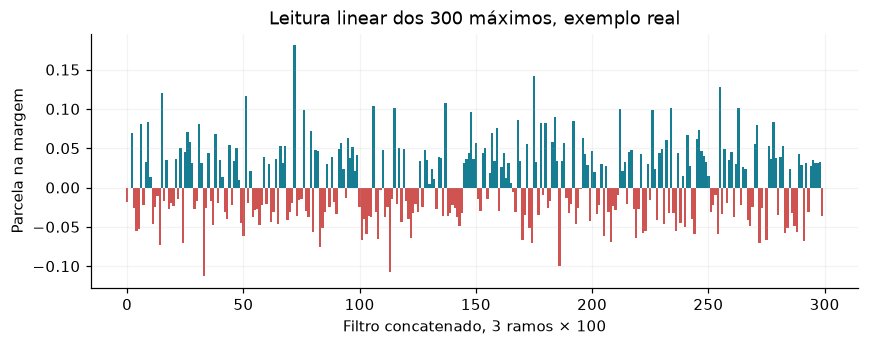

In [26]:
e=exemplos[2];r=e["cnn_readout"]
parcelas=pd.DataFrame(r["filter_contributions"])
soma=float(parcelas.contribution.sum()+r["bias_margin"])
conferir("As 300 parcelas reconstroem a margem real da CNN",len(parcelas)==300 and abs(soma-r["logit_margin"])<1e-5)
print(e["text"])
print({"margem registrada":r["logit_margin"],"margem reconstruída":soma})
display(pd.DataFrame(r["positive_windows"]+r["negative_windows"])[["words","kernel","contribution"]])
fig,ax=plt.subplots(figsize=(9,3))
x=np.arange(len(parcelas));ax.bar(x,parcelas.contribution,color=np.where(parcelas.contribution>=0,CORES[0],CORES[3]),width=1)
ax.set(xlabel="Filtro concatenado, 3 ramos × 100",ylabel="Parcela na margem",title="Leitura linear dos 300 máximos, exemplo real")
plt.show()

<a id="mecanismos"></a>
## 9. MLPs, resíduos, inicialização e regularização

Este bloco usa **outro estudo controlado**, com 51 treinos. Seu objetivo é observar
mecanismos do livro, sem fazer ranking entre MLP e CNN. A entrada é o texto completo
em TF-IDF de 12 mil features, projetado por SVD para 128 dimensões e padronizado.
Vocabulário, IDF, SVD e padronização foram ajustados só nos 6.144 exemplos de treino.

A MLP abaixo é a classe exata do estudo. O ramo residual soma `h + escala × correção`.
As redes de 12 camadas têm os mesmos mapas aprendidos, pesos iniciais e número de
parâmetros; varia a soma e a escala. A escala usada foi `1/sqrt(número_de_blocos)`.
Não incluímos normalização como um fator adicional escondido.

In [27]:
class TeachingMLP(nn.Module):
    """Same learned maps for plain/residual controls; no normalization confound."""
    def __init__(self, input_dim, width, depth, residual=False, residual_scale=1.0, dropout=0.0):
        super().__init__()
        self.spec = {"input_dim": input_dim, "width": width, "depth": depth, "residual": residual,
                     "residual_scale": residual_scale, "dropout": dropout}
        self.stem = nn.Linear(input_dim, width)
        self.blocks = nn.ModuleList(nn.Linear(width, width) for _ in range(depth - 1))
        self.head = nn.Linear(width, 2)
        self.drop = nn.Dropout(dropout)
        self.residual, self.residual_scale = residual, float(residual_scale)
        for layer in [self.stem, *self.blocks]:
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu"); nn.init.zeros_(layer.bias)
        nn.init.normal_(self.head.weight, std=1 / math.sqrt(width)); nn.init.zeros_(self.head.bias)

    def forward(self, x):
        h = self.stem(x)
        for layer in self.blocks:
            correction = layer(self.drop(F.relu(h)))
            h = h + self.residual_scale * correction if self.residual else correction
        return self.head(self.drop(F.relu(h)))

In [28]:
def representacao_mlp(textos_treino, textos_outros):
    # Receita do estudo real, definida para leitura. Não é reajustada na auditoria.
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import StandardScaler
    tf=TfidfVectorizer(max_features=12000,min_df=2,ngram_range=(1,2),sublinear_tf=True)
    tr=tf.fit_transform(textos_treino)
    svd=TruncatedSVD(n_components=128,n_iter=7,random_state=20261102)
    z=svd.fit_transform(tr)
    pad=StandardScaler().fit(z)
    return pad.transform(z),pad.transform(svd.transform(tf.transform(textos_outros)))

dcfg=read_json("didactic_config.json")
ds=read_json("results/didactic/summary.json")
registros_mlp=[read_json(n) for n in ARQUIVOS.namelist() if n.startswith("results/didactic/runs/") and n.endswith(".json")]
tabela=[]
for depth,residual,escala in [(1,False,1.),(4,False,1.),(12,False,1.),(12,True,1.),(12,True,1/math.sqrt(11))]:
    m=TeachingMLP(128,64,depth,residual,escala)
    tabela.append({"camadas":depth,"residual":residual,"escala":escala,"parâmetros":sum(p.numel() for p in m.parameters())})
display(pd.DataFrame(tabela))
display(pd.DataFrame(ds["internal_audit"]).query("group == 'architectures'")[["name","parameters","accuracy_mean","ce_mean"]])
# Na mesma semente, os três modelos profundos partem das mesmas matrizes.
for seed in dcfg["seeds"]:
    rr=[r for r in registros_mlp if r["group"]=="architectures" and r["seed"]==seed and r["spec"]["depth"]==12]
    conferir(f"MLPs profundas têm partida pareada, semente {seed}",len(rr)==3 and len({r["initial_state_sha256"] for r in rr})==1)

,camadas,residual,escala,parâmetros
0,1,False,1.000000,8386
1,4,False,1.000000,20866
2,12,False,1.000000,54146
3,12,True,1.000000,54146
4,12,True,0.301511,54146


,name,parameters,accuracy_mean,ce_mean
0,plain_12,54146,0.781087,1.590655
1,plain_1,8386,0.857747,0.336844
2,plain_4,20866,0.824219,0.651852
3,residual_12_raw,54146,0.656413,1.071896
4,residual_12_scaled,54146,0.831543,0.525383


### A taxa também tem geometria

Na função quadrática `L(x,y) = (0,5 x² + 20 y²)/2`, as curvaturas são 0,5 e 20.
O gradiente descendente tem condição de estabilidade `0 < taxa < 2/20 = 0,1`.
O caminho em zigue-zague vem de direções com curvaturas diferentes.
Este exemplo determinístico usa taxas escolhidas para ilustrar geometria;
a comparação controlada de minibatches é a dos experimentos no IMDb.

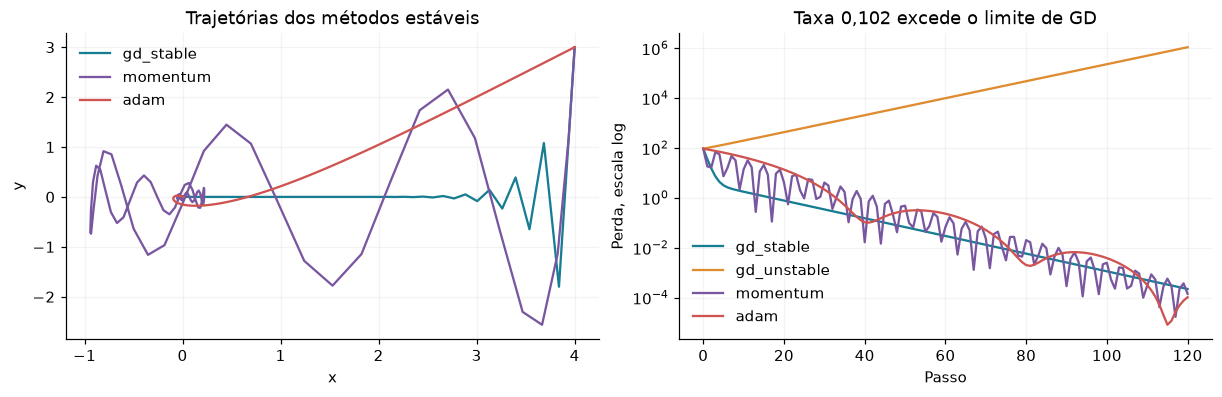

In [29]:
def otimizar_quadratica(nome,taxa,momentum=0.):
    x=torch.tensor([4.,3.],dtype=torch.float64,requires_grad=True)
    opt=torch.optim.Adam([x],lr=taxa) if nome=="adam" else torch.optim.SGD([x],lr=taxa,momentum=momentum)
    saidas=[]
    for passo in range(121):
        perda=(.5*x[0].square()+20*x[1].square())/2
        saidas.append([passo,*x.detach().tolist(),float(perda.detach())])
        if passo<120:
            opt.zero_grad();perda.backward();opt.step()
    return pd.DataFrame(saidas,columns=["step","x","y","loss"])

quadratica=read_csv("results/didactic/quadratic.csv")
nova=otimizar_quadratica("sgd",.08)
esperado=quadratica[quadratica.condition=="gd_stable"]
conferir("Quadrática reconstruída por gradiente em CPU",np.allclose(nova.loss,esperado.loss,atol=1e-12))
fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
for i,(nome,rr) in enumerate(quadratica.groupby("condition",sort=False)):
    if nome!="gd_unstable": axes[0].plot(rr.x,rr.y,label=nome,color=CORES[i])
    axes[1].plot(rr.step,rr.loss,label=nome,color=CORES[i])
axes[0].set(xlabel="x",ylabel="y",title="Trajetórias dos métodos estáveis");axes[0].legend(frameon=False)
axes[1].set(xlabel="Passo",ylabel="Perda, escala log",yscale="log",title="Taxa 0,102 excede o limite de GD");axes[1].legend(frameon=False)
plt.show()

### Inicialização: o sinal e o gradiente atravessam as camadas?

Na inicialização He para ReLU, a variância dos pesos é `2/largura`.
Multiplicamos a mesma matriz gaussiana por ganhos 0,1, 1 e 3. Entradas, matrizes
de base e leitura final são iguais por semente. Esse diagnóstico não treina a rede.
A escala afeta a propagação das ativações e dos gradientes; He é uma aproximação
para preservar escala, não uma garantia em toda rede finita.

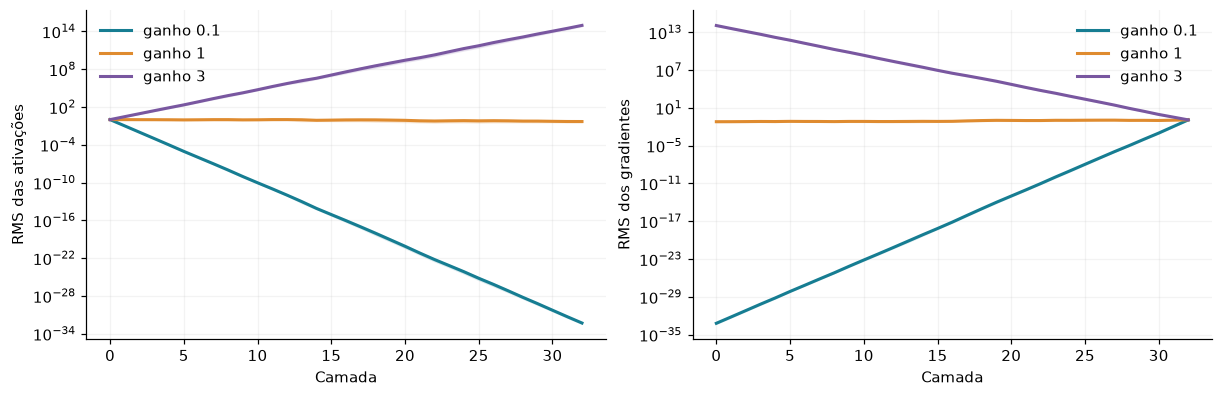

In [30]:
def diagnostico_inicializacao(seed,gain,width=64,depth=32,n=256):
    gerador=torch.Generator().manual_seed(seed)
    origem=torch.randn(n,width,generator=gerador,dtype=torch.float64)
    pesos=[torch.randn(width,width,generator=gerador,dtype=torch.float64) for _ in range(depth)]
    leitura=torch.randn(width,generator=gerador,dtype=torch.float64);leitura/=leitura.norm()
    h=origem.clone().requires_grad_(True);valores=[h]
    for peso in pesos:
        h=torch.relu(h@(gain*math.sqrt(2/width)*peso));h.retain_grad();valores.append(h)
    (h@leitura).sum().backward()
    return pd.DataFrame([{"layer":i,"activation_rms":float(h.detach().square().mean().sqrt()),
                          "gradient_rms":float(h.grad.square().mean().sqrt())} for i,h in enumerate(valores)])

ini=read_csv("results/didactic/initialization.csv")
reconstruida=diagnostico_inicializacao(17,1.)
referencia=ini[(ini.seed==17)&(ini.gain==1.)]
conferir("Inicialização e gradientes reconstruídos em CPU",np.allclose(reconstruida.gradient_rms,referencia.gradient_rms,rtol=1e-10,atol=1e-14))
fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
for j,metrica in enumerate(["activation_rms","gradient_rms"]):
    for i,(ganho,rr) in enumerate(ini.groupby("gain")):
        faixa(axes[j],rr,"layer",metrica,f"ganho {ganho:g}",CORES[i])
    axes[j].set(xlabel="Camada",ylabel=["RMS das ativações","RMS dos gradientes"][j],yscale="log");axes[j].legend(frameon=False)
plt.show()

### Regularização e parada pela validação

No estudo MLP de 512 resenhas, comparamos ausência de regularização, dropout 0,5
e penalidade L2 explícita. A perda com L2 é `CE + λ/2 × soma(pesos_lineares²)`;
vieses ficam fora da penalidade. Aqui Adam tem `weight_decay=0`. Isso não é a
mesma operação que AdamW com decay desacoplado.

A regra de parada usa paciência 15 e melhora mínima 0,0001 na validação.
Continuamos calculando a trajetória longa para enxergar o que ocorreria depois,
mas o checkpoint de parada não consulta essas épocas futuras. Selecionar por CE
não garante a maior acurácia de auditoria em cada execução.

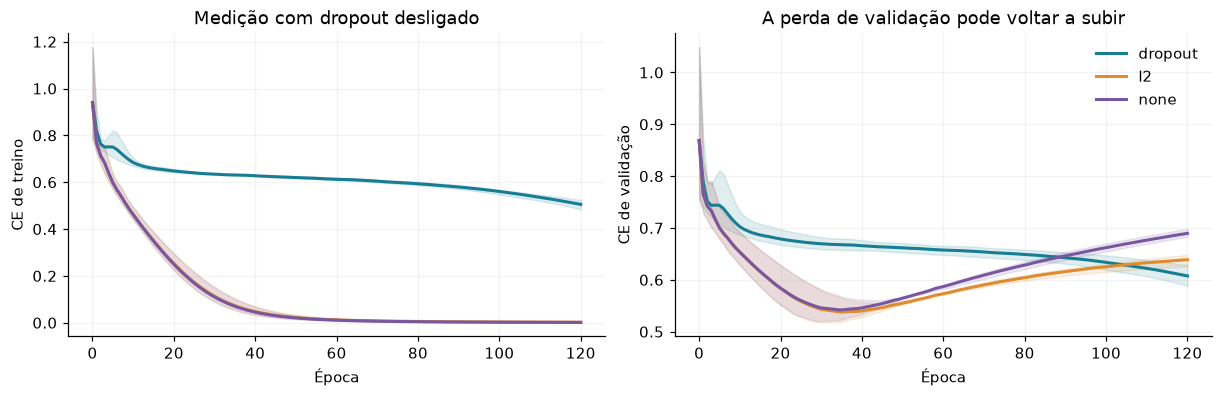

,variante,semente,época escolhida,parada virtual
0,dropout,17,120,120
1,dropout,29,120,120
2,dropout,43,120,120
3,l2,17,30,45
4,l2,29,44,59
5,l2,43,34,49
6,none,17,30,45
7,none,29,43,58
8,none,43,34,49


,name,checkpoint,accuracy_mean,ce_mean
8,dropout,final,0.718424,0.610605
9,dropout,early,0.718424,0.610605
10,l2,final,0.761393,0.699044
11,l2,early,0.724609,0.561163
12,none,final,0.754557,0.754681
13,none,early,0.722168,0.565271


In [31]:
def objetivo_com_l2(rede,logits,labels,lam):
    penalidade=sum(camada.weight.square().sum() for camada in rede.modules() if isinstance(camada,nn.Linear))
    return F.cross_entropy(logits,labels)+lam*.5*penalidade

reg=[r for r in registros_mlp if r["group"]=="regularization"]
fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
curvas=pd.DataFrame([{**h,"variante":r["name"],"seed":r["seed"]} for r in reg for h in r["history"]])
for i,(nome,rr) in enumerate(curvas.groupby("variante")):
    faixa(axes[0],rr,"epoch","train_ce",nome,CORES[i]);faixa(axes[1],rr,"epoch","validation_ce",nome,CORES[i])
axes[0].set(xlabel="Época",ylabel="CE de treino",title="Medição com dropout desligado")
axes[1].set(xlabel="Época",ylabel="CE de validação",title="A perda de validação pode voltar a subir");axes[1].legend(frameon=False);plt.show()
display(pd.DataFrame([{ "variante":r["name"],"semente":r["seed"],"época escolhida":r["early_epoch"],
                       "parada virtual":r["virtual_stop_epoch"]} for r in reg]))
display(pd.DataFrame(ds["internal_audit"]).query("group == 'regularization'")[["name","checkpoint","accuracy_mean","ce_mean"]])

<a id="double-descent"></a>
## 10. Double descent: um caso em que podemos ver a interpolação

Este experimento é **regressão sintética**, separado das classificações do IMDb.
A função verdadeira é `x₀ + 0,5 sin(x₁)`, com ruído de desvio 0,3.
Temos 64 exemplos de treino e 2.048 de teste sintético.

Sorteamos uma camada ReLU oculta e a **congelamos**. Variamos `p`, o número de
features/coeficientes da saída. Ajustamos somente esses coeficientes por mínimos
quadrados de norma mínima ou ridge. As features são aninhadas entre larguras.
Não é uma CNN treinada ponta a ponta.

No limiar `p ≈ n`, a matriz de features pode ficar mal condicionada. Interpolar
também o ruído pode exigir coeficientes grandes. Mais features podem reduzir a
norma da solução e o erro voltar a cair. O gráfico inclui todas as 20 sementes
e 22 larguras previstas, sem escolher uma semente pelo teste.

In [32]:
def ridge_weights(phi, y, lam, rcond=1e-12):
    u, s, vt = svd(phi, full_matrices=False, check_finite=True, lapack_driver="gesdd")
    active = s > rcond * s[0]
    if lam == 0:
        factors = np.zeros_like(s); factors[active] = 1 / s[active]
    else:
        factors = s / (s * s + len(phi) * lam)
    weights = vt.T @ (factors * (u.T @ y))
    effective_df = float(active.sum()) if lam == 0 else float(np.sum(s * s / (s * s + len(phi) * lam)))
    return weights, {"rank": int(active.sum()), "effective_df": effective_df,
                     "s_max": float(s[0]), "s_min": float(s[-1]), "condition_number": float(s[0] / s[-1])}


def synthetic_case(seed, spec):
    rng = np.random.default_rng(seed)
    x = rng.normal(size=(spec["train_n"], spec["input_dim"]))
    xt = rng.normal(size=(spec["test_n"], spec["input_dim"]))
    f = x[:, 0] + .5 * np.sin(x[:, 1]); ft = xt[:, 0] + .5 * np.sin(xt[:, 1])
    y = f + spec["noise_sd"] * rng.normal(size=len(x))
    yt = ft + spec["noise_sd"] * rng.normal(size=len(xt))
    w = rng.normal(size=(spec["input_dim"], max(spec["widths"]))) / math.sqrt(spec["input_dim"])
    return x, xt, y, yt, f, ft, w

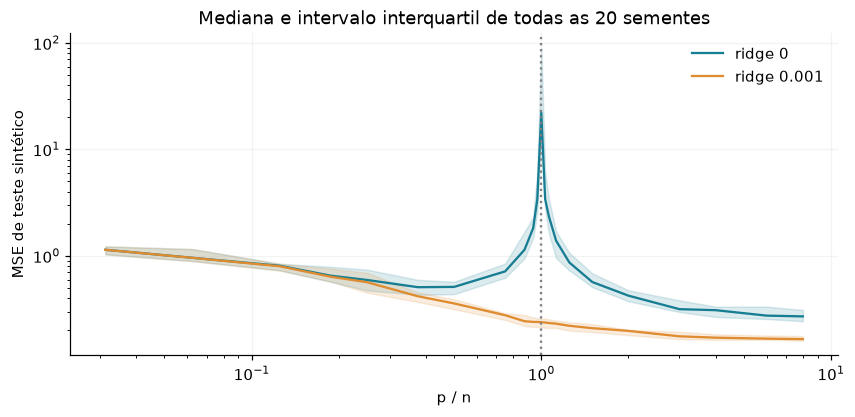

,train_mse,test_mse,coefficient_norm
p,,,
24,1.781083e-01,0.508172,11.283079
64,9.964787e-29,22.090608,150.435749
512,1.096138e-29,0.270269,15.043844


{'MSE de treino': 1.4360226883972926e-28, 'MSE de teste': 19.405437340852753, 'norma dos coeficientes': 138.26734676804313}
Isto demonstra double descent neste problema sintético; não o estabelecemos na CNN do IMDb.


In [33]:
dd=read_csv("results/didactic/double_descent.csv")
conferir("Todas as 880 condições sintéticas preservadas",len(dd)==880 and set(dd.seed)==set(dcfg["double_descent"]["seeds"]))
fig,ax=plt.subplots(figsize=(9,3.8))
for i,(lam,rr) in enumerate(dd.groupby("lambda")):
    g=rr.groupby("p_over_n").test_mse
    ax.plot(g.median().index,g.median().values,label=f"ridge {lam:g}",color=CORES[i])
    ax.fill_between(g.median().index,g.quantile(.25).values,g.quantile(.75).values,color=CORES[i],alpha=.15)
ax.axvline(1,ls=":",color="gray");ax.set(xscale="log",yscale="log",xlabel="p / n",ylabel="MSE de teste sintético",
    title="Mediana e intervalo interquartil de todas as 20 sementes");ax.legend(frameon=False);plt.show()
display(dd[(dd["lambda"]==0)&dd.p.isin([24,64,512])].groupby("p")[["train_mse","test_mse","coefficient_norm"]].median())

# Reconstruímos a primeira semente predefinida, não uma semente escolhida pelo gráfico.
spec=dcfg["double_descent"];x,xt,y,yt,_,_,ocultos=synthetic_case(spec["seeds"][0],spec)
p=64;phi=np.maximum(x@ocultos[:,:p],0)/math.sqrt(p)
phi_t=np.maximum(xt@ocultos[:,:p],0)/math.sqrt(p)
beta,diagnostico=ridge_weights(phi,y,0.,spec["rcond"])
mse=float(np.mean((phi_t@beta-yt)**2))
esperado=dd[(dd.seed==101)&(dd.p==64)&(dd["lambda"]==0)].iloc[0]
conferir("Interpolador sintético reconstruído",np.max(np.abs(phi@beta-y))<1e-8)
conferir("MSE de teste sintético reconstruído",np.isclose(mse,esperado.test_mse,rtol=1e-8))
print({"MSE de treino":float(np.mean((phi@beta-y)**2)),"MSE de teste":mse,"norma dos coeficientes":float(np.linalg.norm(beta))})
print("Isto demonstra double descent neste problema sintético; não o estabelecemos na CNN do IMDb.")

<a id="qwen"></a>
## 11. Qwen3-8B: classificar, extrair vetores e intervir

Usamos o mesmo modelo congelado em três papéis. **Classificação:** o prompt pede
`negative` ou `positive`; comparamos os escores desses dois próximos tokens.
Não treinamos uma cabeça nova e não fizemos fine-tuning. **Extração:** capturamos
estados internos de 4.096 dimensões. **Geração:** ele escreve token por token.

A probabilidade mostrada na classificação é normalizada entre os dois rótulos
candidatos. Ela não representa toda a distribuição do vocabulário. No experimento
original, a temperatura foi calibrada separadamente.

O objetivo do steering é didático: modificar uma ativação mantendo pesos, texto
e prompt fixos. A analogia com GANs e flows é a intervenção na representação.
No Transformer há um estado por token e por camada, não um único código global
com uma transformação obrigatoriamente invertível.

In [34]:
def label_ids(tokenizer):
    result = []
    for word in ("negative", "positive"):
        ids = tokenizer.encode(word, add_special_tokens=False)
        if len(ids) != 1:
            raise ValueError(f"The label {word!r} is not a single token: {ids}")
        result.append(ids[0])
    return result

def probabilidades_dos_rotulos(logits_vocabulario,ids_dos_rotulos):
    selecionados=logits_vocabulario[...,ids_dos_rotulos]
    return torch.softmax(selecionados,dim=-1)

# Exemplo numérico inventado para explicar a normalização, sem inferência do Qwen.
exemplo_logits=torch.tensor([0.,2.,-1.,3.])
print("Normalização entre dois rótulos fictícios:",probabilidades_dos_rotulos(exemplo_logits,[1,3]).tolist())
qmeta=read_json("results/qwen_improved/test/model_metadata.json")
print({"modelo":qmeta["model"]["model_id"],"parâmetros":qmeta["parameters"],
       "parâmetros treináveis":qmeta["trainable_parameters"]})

Normalização entre dois rótulos fictícios: [0.2689414322376251, 0.7310585975646973]
{'modelo': 'Qwen/Qwen3-8B', 'parâmetros': 8190735360, 'parâmetros treináveis': 0}


### De onde veio a direção escolhida?

Na demonstração final, usamos **128 enredos sintéticos de treino**. Cada enredo
aparece com uma instrução positiva e com uma negativa, dando 256 estados internos.
Capturamos a última posição do prompt no bloco 28, com o Qwen congelado.
Não são rótulos de sentimento de 256 resenhas: os grupos são as duas instruções.

Calculamos `d = média(h | instrução positiva) − média(h | instrução negativa)`
e `v = d / ||d||`. A escala selecionada foi a norma de `d`, cerca de 100,85.
Na intervenção usamos `h' = h + α × escala × v`, com α = −2, 0, +2.
Camada, direção, amplitude e fase foram escolhidas na validação da geração,
antes das 64 novas fontes da demonstração.

O anexo do notebook contém **os 256 estados reais completos** e o vetor selecionado.
A célula seguinte refaz a direção em CPU, sem carregar oito bilhões de parâmetros.

In [35]:
qf=read_json("results/qwen_improved/selection_frozen.json")["selected"]
qinfo=read_json("results/qwen_improved/selected_training_features.json")["directions"][0]
estados=read_npz("results/qwen_improved/selected_training_features.npz")
camada=qinfo["layer"]
h_treino=estados[f"train_L{camada}"].astype(np.float64)
y_instrucao=estados[f"train_labels_L{camada}"]
d=h_treino[y_instrucao==1].mean(0)-h_treino[y_instrucao==0].mean(0)
direcao=d/np.linalg.norm(d)
salva=read_npz("derived/selected_qwen_direction.npz")["direction"]
conferir("Direção real de 4.096 dimensões reconstruída das médias",np.allclose(direcao,salva,atol=1e-10,rtol=1e-10))
escala=float(qf["positive"]["layers"][0][2]);alfa=float(qf["positive"]["gain"])
conferir("Escala corresponde à norma da diferença de médias",np.isclose(np.linalg.norm(d),escala,atol=1e-10))
display(pd.DataFrame([{"instrução":int(y),"estados":int((y_instrucao==y).sum())} for y in [0,1]]))
print({"bloco":camada,"dimensões":len(direcao),"norma de v":float(np.linalg.norm(direcao)),"escala":escala,"alfa":alfa})

,instrução,estados
0,0,128
1,1,128


{'bloco': 28, 'dimensões': 4096, 'norma de v': 1.0, 'escala': 100.85103234900045, 'alfa': 2.0}


### O deslocamento é uma soma numa ativação

A direção não é um novo peso. Ela é somada ao estado calculado numa execução
do modelo. A projeção sobre `v` muda em `α × escala`, pois `v` tem norma um.
A componente ortogonal ao vetor fica igual nesse ponto da rede. As camadas
seguintes podem transformar essa mudança de maneira não linear.

,alfa,projeção em v,norma do deslocamento
0,-2.0,-239.873130,201.702065
1,0.0,-38.171065,0.000000
2,2.0,163.531000,201.702065


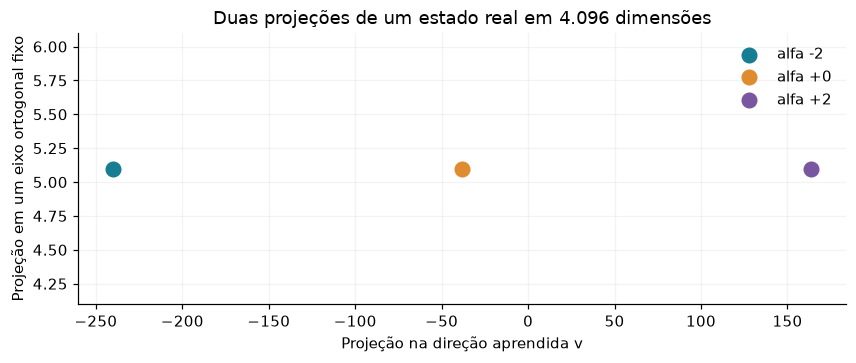

In [36]:
h=h_treino[0]
tabela=[]
for a in [-alfa,0,alfa]:
    novo=h+a*escala*direcao
    tabela.append({"alfa":a,"projeção em v":float(novo@direcao),"norma do deslocamento":float(np.linalg.norm(novo-h))})
    ortogonal=novo-(novo@direcao)*direcao
    conferir(f"Soma preserva componente ortogonal, alfa {a:g}",np.allclose(ortogonal,h-(h@direcao)*direcao,atol=1e-10))
display(pd.DataFrame(tabela))
rng=np.random.default_rng(7);perpendicular=rng.normal(size=len(direcao))
perpendicular-=direcao*(perpendicular@direcao);perpendicular/=np.linalg.norm(perpendicular)
fig,ax=plt.subplots(figsize=(9,3.2))
for i,a in enumerate([-alfa,0,alfa]):
    novo=h+a*escala*direcao
    ax.scatter(novo@direcao,novo@perpendicular,s=90,color=CORES[i],label=f"alfa {a:+g}")
ax.set(xlabel="Projeção na direção aprendida v",ylabel="Projeção em um eixo ortogonal fixo",
       title="Duas projeções de um estado real em 4.096 dimensões")
ax.set_ylim(float(h@perpendicular)-1,float(h@perpendicular)+1)
ax.ticklabel_format(axis="y",style="plain",useOffset=False)
ax.legend(frameon=False);plt.show()

### Como um hook faz a soma, e quando ele atua

No código de geração, registramos um hook na saída do bloco escolhido. O hook
devolve o estado modificado para os blocos seguintes. Ao sair do contexto, removemos
o hook, inclusive em caso de erro. Os pesos ficam congelados.

Na rodada final do Qwen, o controlador só é ativado **depois que o modelo gera
`REVIEW:`**. Até esse ponto, o campo FACT tem os mesmos tokens nas três condições.
Depois, a soma se repete em cada passo de decodificação. Não editamos palavras
depois de gerar a saída.

O exemplo executável abaixo isola a operação do hook numa camada linear pequena
em CPU. A máscara de fase é explícita. Ele explica a operação, sem simular uma
nova geração do Qwen. A implementação de produção também gerencia o cache e o
marcador gerado em cada linha do lote.

In [37]:
class SomaNaAtivacao:
    def __init__(self,bloco,vetor,alpha,scale,mask):
        self.bloco,self.vetor,self.alpha,self.scale,self.mask=bloco,vetor,alpha,scale,mask
    def __enter__(self):
        def hook(modulo,entradas,saida):
            h=saida[0] if isinstance(saida,tuple) else saida
            novo=h+self.mask[...,None].to(h.dtype)*(self.alpha*self.scale*self.vetor.to(h))
            return (novo,)+saida[1:] if isinstance(saida,tuple) else novo
        self.handle=self.bloco.register_forward_hook(hook)
        return self
    def __exit__(self,*erro): self.handle.remove()

bloco_aula=nn.Linear(8,8,bias=False).requires_grad_(False).eval()
entrada_hook=torch.randn(1,4,8)
eixo=torch.arange(1,9,dtype=torch.float32);eixo/=eixo.norm()
fase=torch.tensor([[False,False,True,True]])
sem=bloco_aula(entrada_hook);pesos_antes=bloco_aula.weight.clone()
with SomaNaAtivacao(bloco_aula,eixo,2.,.5,fase): com=bloco_aula(entrada_hook)
conferir("Hook deixa intactas as posições anteriores à fase",torch.equal(com[:,:2],sem[:,:2]))
conferir("Hook soma somente no estado ativo",torch.allclose(com[:,2:]-sem[:,2:],eixo.expand(1,2,-1),atol=1e-6))
conferir("Intervenção não altera pesos",torch.equal(bloco_aula.weight,pesos_antes))
conferir("Hook removido ao sair do contexto",torch.equal(bloco_aula(entrada_hook),sem))
print("Operação e remoção do hook verificadas em CPU.")

Operação e remoção do hook verificadas em CPU.


### Mesma fonte e mesmo prompt, três saídas reais

O primeiro caso sintético na ordem pré-fixada mostra as três gerações completas.
O segundo caso exibido foi definido previamente para leitura e contém uma falha
factual anotada: a intervenção positiva inventa uma cidade pequena e uma época
mágica do ano. A leitura qualitativa é do assistente, sem anotação humana independente.
Prefixo FACT idêntico não garante que toda a saída seja factual.

In [38]:
trios=read_json("derived/qwen_64_trios.json")
nomes_q=[qf["negative"]["name"],"baseline",qf["positive"]["name"]]
rotulos_q=["Intervenção negativa, α = −2","Sem steering, α = 0","Intervenção positiva, α = +2"]
mapa_q={(r["id"],r["condition"]):r for r in trios}
ids_q=list(dict.fromkeys(r["id"] for r in trios))
def mostrar_caso_qwen(identificador):
    casos=[mapa_q[identificador,nome] for nome in nomes_q]
    # Textos de fonte reais são abreviados no roteiro. As saídas permanecem integrais.
    fonte=casos[0]["source"]
    if identificador.startswith("imdb_"):fonte=" ".join(fonte.split()[:20])+" […]"
    display(HTML("<h4>"+html.escape(identificador)+"</h4><p>"+html.escape(fonte)+"</p>"))
    linhas="".join("<tr><td style='width:22%;vertical-align:top;padding:10px'>"+html.escape(rotulo)+
                   "</td><td style='white-space:pre-wrap;padding:10px'>"+html.escape(r["generated"])+"</td></tr>"
                   for rotulo,r in zip(rotulos_q,casos))
    display(HTML("<table style='width:100%;border-collapse:collapse'>"+linhas+"</table>"))
    prefixos=[r["generated"].split("REVIEW:",1)[0] for r in casos]
    conferir("FACT idêntico no caso "+identificador,len(set(prefixos))==1)
primeiro_sintetico=next(r["id"] for r in trios if r.get("kind")=="synthetic_neutral_plot")
mostrar_caso_qwen(primeiro_sintetico)
mostrar_caso_qwen("imdb_test_05223")
print("O anexo contém todos os 64 trios. Para explorar: mostrar_caso_qwen(ids_q[10])")

"Intervenção negativa, α = −2","FACT: In the film Signal 2040, Bela, a pilot in a mountain village, discovers an empty theater. With help from Evan, Bela works to organize a performance before the town festival ends. REVIEW: The film's direction lacks coherence and the pacing feels disjointed."
"Sem steering, α = 0","FACT: In the film Signal 2040, Bela, a pilot in a mountain village, discovers an empty theater. With help from Evan, Bela works to organize a performance before the town festival ends. REVIEW: The film's storytelling is engaging with a steady pace."
"Intervenção positiva, α = +2","FACT: In the film Signal 2040, Bela, a pilot in a mountain village, discovers an empty theater. With help from Evan, Bela works to organize a performance before the town festival ends. REVIEW: The film offers a thoughtful blend of gentle storytelling and warm performances."


"Intervenção negativa, α = −2","FACT: The source mentions a film that is described as possibly the worst ever made, with comparisons to Plan 9 From Outer Space and criticism of its production and content. REVIEW: The film's direction and storytelling feel desperate and unconvincing."
"Sem steering, α = 0","FACT: The source mentions a film that is described as possibly the worst ever made, with comparisons to Plan 9 From Outer Space and criticism of its production and content. REVIEW: The film's direction and storytelling lack coherence and originality."
"Intervenção positiva, α = +2","FACT: The source mentions a film that is described as possibly the worst ever made, with comparisons to Plan 9 From Outer Space and criticism of its production and content. REVIEW: The film is a unique blend of heartfelt storytelling and creative direction that beautifully captures the essence of a small town during a magical time of year."


O anexo contém todos os 64 trios. Para explorar: mostrar_caso_qwen(ids_q[10])


### Avaliação, controles e direção antiga

A avaliação usa 64 fontes e 11 condições, incluindo três direções aleatórias com
norma de deslocamento equivalente. O juiz sem steering é o próprio Qwen congelado.
Portanto, sucesso no diagnóstico automático não é acurácia contra uma referência
humana independente. Não estamos demonstrando superioridade sobre prompting.

A tentativa original usou outra direção, obtida por **RFM/AGOP** em 512 resenhas
rotuladas: ajustamos um preditor auxiliar, juntamos gradientes por exemplo e buscamos
o principal eixo de `AGOP = média(gradiente × gradienteᵀ)`. Esse preditor não alterou
os pesos do Qwen. Uma direção útil na classificação não controlou a geração de
maneira confiável. A demonstração final usa a diferença de médias de instruções.

Não reconstruímos a AGOP original aqui, pois seu artefato completo tem 31 MB. O código abaixo
explica a álgebra numérica com um gradiente auxiliar pequeno. O notebook específico
de steering preserva a reconstrução completa da direção antiga.

In [39]:
semantica=read_json("results/qwen_improved/semantic_analysis.json")
conj=semantica["paired_comparisons"]["all"]["joint_target_success"]
display(pd.DataFrame([{ "controlador":nome,"duas direções no sentido-alvo":r["mean"],"fontes":r["n"]} for nome,r in conj.items()]))
display(pd.DataFrame([r for r in semantica["conditions"] if r["condition"] in nomes_q and r["group"]=="all"])[
    ["condition","target_rate","supported_facts_n","unsupported_facts_n","unclear_facts_n"]])
print("Juiz automático:",semantica["provenance"])
print("55/64 no diagnóstico conjunto dos dois sentidos. Há falhas, inclusive factuais.")
gradientes_aula=np.array([[1.,2.,0.],[2.,4.,.1],[1.5,3.,-.1]])
agop=gradientes_aula.T@gradientes_aula/len(gradientes_aula)
autovalores,eixos=np.linalg.eigh(agop)
print("AGOP ilustrativa 3 × 3:");display(agop)
print("Eixo principal ilustrativo:",eixos[:,-1],"| autovalor:",autovalores[-1])

,controlador,duas direções no sentido-alvo,fontes
0,selected,0.859375,64
1,original,0.000000,64
2,random_1,0.000000,64
3,random_2,0.000000,64
4,random_3,0.031250,64


,condition,target_rate,supported_facts_n,unsupported_facts_n,unclear_facts_n
0,baseline,NaN,64,0,0
1,intent_256_L28_means_contrast_g+2_last_all_fielded_1_-1,0.906250,64,0,0
2,intent_256_L28_means_contrast_g+2_last_all_fielded_1_+1,0.921875,54,10,0


Juiz automático: Automatic diagnostic by frozen Qwen3-8B with no steering hooks. Same base model as generator; not an independent human evaluation.
55/64 no diagnóstico conjunto dos dois sentidos. Há falhas, inclusive factuais.
AGOP ilustrativa 3 × 3:


array([[2.41666667e+00, 4.83333333e+00, 1.66666667e-02],
       [4.83333333e+00, 9.66666667e+00, 3.33333333e-02],
       [1.66666667e-02, 3.33333333e-02, 6.66666667e-03]])

Eixo principal ilustrativo: [-0.44721147 -0.89442293 -0.00308589] | autovalor: 12.083448338218467


<a id="originais"></a>
## 12. O estudo original, calibração e limites

O projeto começou com TF-IDF, CNN e BERT e acrescentou Qwen congelado. A tabela
abaixo é do **teste oficial original com 25 mil resenhas**, diferente das
auditorias internas usadas para discutir mecanismos. Lemos resultados já salvos;
este notebook não abre o corpus oficial de teste nem faz nova seleção por ele.

Na execução original, o TF-IDF recebe o texto completo, a CNN até 400 tokens,
BERT até 192 WordPieces e Qwen até 768 tokens de fonte. Por isso os números
não isolam a arquitetura como único fator. A extensão Qwen também reutilizou
um teste já examinado e tem caráter exploratório.

In [40]:
orig=read_csv("results/comparison.csv")
orig=orig[(orig.split=="test")&(orig.probabilities=="calibrated")]
qmet=read_json("results/qwen/classification/metrics.json")["test"]["calibrated"]
tabela_original=[{"modelo":r["model"],"acurácia":r["accuracy"],"F1 macro":r["f1_macro"],"CE":r["log_loss"]}
                for r in orig.to_dict("records")]
tabela_original.append({"modelo":"Qwen3-8B congelado","acurácia":qmet["accuracy"],"F1 macro":qmet["f1_macro"],"CE":qmet["log_loss"]})
display(pd.DataFrame(tabela_original))
print("As auditorias didáticas e o teste oficial são protocolos distintos.")

,modelo,acurácia,F1 macro,CE
0,bert,0.90944,0.909414,0.227835
1,cnn,0.86784,0.867817,0.303703
2,tfidf,0.90144,0.901440,0.239638
3,Qwen3-8B congelado,0.95260,0.952600,0.136682


As auditorias didáticas e o teste oficial são protocolos distintos.


### A confiança pode melhorar sem mudar a classe

A calibração de temperatura divide a margem por um escalar positivo aprendido
só no conjunto de calibração. Isso muda probabilidades, CE e Brier, preservando
o sinal da margem e a decisão de limiar 0,5. O gráfico compara as probabilidades
médias com a fração positiva observada em cada faixa.

No trabalho original também exploramos agrupamento semântico e termos frequentes
dos clusters. Um cluster descreve similaridade de resenhas; não é uma nova classe
de sentimento validada. Isso permanece análise descritiva, não escolha de modelo.

Outra extensão anterior usou BERT com duas posições MASK e direção RFM para
propor palavras numa resenha. Nesse caso o resultado é uma edição do texto,
preenchida por uma cabeça de masked LM. A demonstração atual do Qwen é uma
geração autoregressiva, com a intervenção nas ativações durante a execução.
Ambas podem falhar em fluência ou conteúdo. Os resultados de uma não medem a outra.

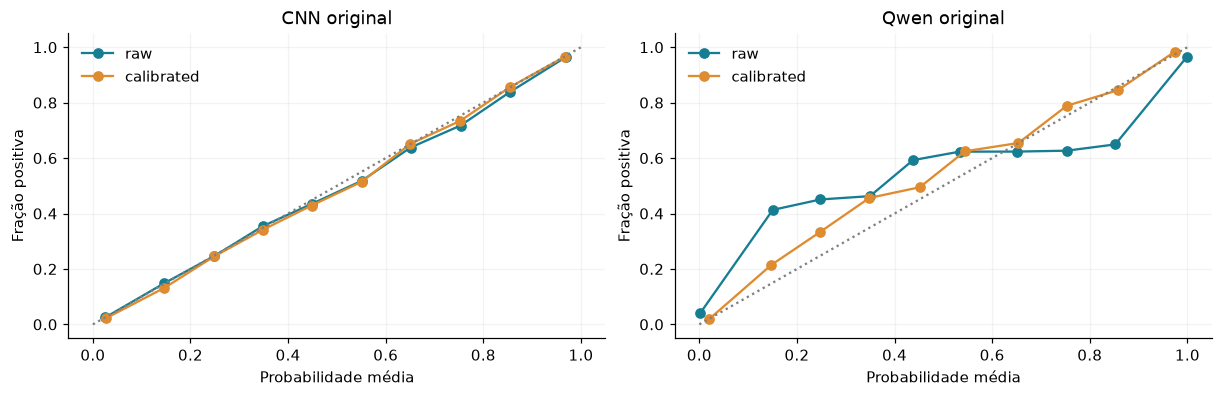

Termos dos clusters originais, análise descritiva:


{'0': ['disney',
  'animation',
  'animated',
  'cartoon',
  'original',
  'characters',
  'like',
  'muppet',
  'kids',
  'story'],
 '1': ['man',
  'police',
  'murder',
  'brother',
  'kill',
  'wife',
  'father',
  'killer',
  'cop',
  'gets'],
 '2': ['movie',
  'funny',
  'comedy',
  'jokes',
  'humor',
  'actor',
  'rock',
  'chris',
  'unfunny',
  'worst'],
 '3': ['film',
  'war',
  'documentary',
  'people',
  'history',
  'american',
  'world',
  'footage',
  'art',
  'political'],
 '4': ['love',
  'woman',
  'young',
  'emma',
  'actress',
  'musical',
  'jane',
  'romantic',
  'film',
  'austen'],
 '5': ['horror',
  'zombie',
  'zombies',
  'movie',
  'gore',
  'bad',
  'horror movie',
  'just',
  'slasher',
  'movies'],
 '6': ['series',
  'episode',
  'season',
  'episodes',
  'shows',
  'match',
  'tv',
  'pilot',
  'betty',
  'like'],
 '7': ['movie',
  'bad',
  'good',
  'acting',
  'movies',
  'film',
  'really',
  'watch',
  'just',
  'story']}

In [41]:
from scipy.optimize import minimize_scalar
def ajustar_temperatura(margens_calibracao,labels_calibracao):
    margens_calibracao=np.asarray(margens_calibracao)
    labels_calibracao=np.asarray(labels_calibracao)
    def objetivo(log_t):
        z=margens_calibracao/np.exp(log_t)
        return np.mean(np.logaddexp(0,z)-labels_calibracao*z)
    ajuste=minimize_scalar(objetivo,bounds=(np.log(.05),np.log(10)),method="bounded")
    if not ajuste.success: raise RuntimeError("Calibração não convergiu")
    return float(np.exp(ajuste.x))

fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
for ax,nome,caminho in [(axes[0],"CNN original","results/cnn/metrics.json"),
                       (axes[1],"Qwen original","results/qwen/classification/metrics.json")]:
    met=read_json(caminho)["test"]
    for i,tipo in enumerate(["raw","calibrated"]):
        bins=pd.DataFrame(met["reliability_"+tipo])
        ax.plot(bins.mean_p_positive,bins.fraction_positive,"o-",color=CORES[i],label=tipo)
    ax.plot([0,1],[0,1],ls=":",color="gray")
    ax.set(xlabel="Probabilidade média",ylabel="Fração positiva",title=nome);ax.legend(frameon=False)
plt.show()
print("Termos dos clusters originais, análise descritiva:")
display(read_json("results/analysis/cluster_terms.json"))

<a id="testes"></a>
## 13. Como conferimos código e resultados

Os `asserts` que executamos verificaram operação da convolução, máscara de padding,
contagem de parâmetros, gradientes, seleção de checkpoint, pooling, congelamento
e intervenção na ativação. Agora reconstruímos as métricas das **49 predições de
auditoria incorporadas**: 43 do estudo sequencial e seis da comparação BPE.

A função abaixo usa logits e rótulos, não métricas prontas como entrada.
Os verificadores completos do repositório também reconstruíram 217 conjuntos
de métricas sequenciais e 18 BPE, incluindo treino/validação. O notebook refaz
a parte de auditoria desses números, e apresenta os certificados da parte restante.
A reavaliação GPU dos checkpoints já foi realizada em outro processo e preservada;
ler seu certificado aqui não é uma nova inferência do modelo.

In [42]:
def metrics(logits, labels):
    z = np.asarray(logits, dtype=np.float64); y = np.asarray(labels, dtype=np.int64)
    p = np.exp(z - z.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
    pred = z.argmax(1)
    return {"accuracy": float(accuracy_score(y, pred)), "ce": float(log_loss(y, p, labels=[0, 1])),
        "f1_macro": float(f1_score(y, pred, average="macro")), "roc_auc": float(roc_auc_score(y, p[:, 1])),
        "brier": float(np.mean((p[:, 1] - y) ** 2)), "correct": int((pred == y).sum())}

audit_seq=read_json("results/sequences/audit_metrics.json")
pred_seq=read_npz("results/sequences/audit_predictions.npz")
verificacoes_metricas=[]
for linha in read_json("results/sequences/verification.json")["audit_metrics"]:
    nome=linha["run_id"]
    z=pred_seq[nome]
    if z.ndim==1: z=np.column_stack([np.zeros_like(z),z])
    met=metrics(z,pred_seq["y"])
    for chave in ["accuracy","ce","f1_macro","brier"]:
        conferir(f"Métrica sequencial: {nome}/{chave}",np.isclose(met[chave],linha[chave],atol=2e-6,rtol=0))
    verificacoes_metricas.append({"estudo":"sequencial","run":nome,**met})
audit_bp=read_json("results/bpe/audit_metrics.json")
pred_bp=read_npz("results/bpe/audit_predictions.npz")
for linha in audit_bp["metrics"]:
    met=metrics(pred_bp[linha["run_id"]],pred_bp["labels"])
    for chave in ["accuracy","ce","f1_macro","brier"]:
        conferir(f"Métrica BPE: {linha['run_id']}/{chave}",np.isclose(met[chave],linha[chave],atol=1e-12,rtol=0))
    verificacoes_metricas.append({"estudo":"BPE","run":linha["run_id"],**met})
conferir("49 conjuntos de métricas de auditoria reconstruídos",len(verificacoes_metricas)==49)
display(pd.DataFrame(verificacoes_metricas).groupby("estudo")[["accuracy","ce"]].agg(["count","min","max"]))
for nome in ["sequences","bpe","didactic","qwen_improved"]:
    evidencia=read_json(f"results/{nome}/verification.json")
    conferir("Certificado científico: "+nome,evidencia["status"]=="passed")
print("Reconstrução de métricas concluída. Os exercícios anteriores também passaram.")

accuracy                        ce                    
              count       min       max count       min       max
estudo                                                           
BPE               6  0.812012  0.823242     6  0.390394  0.411423
sequencial       43  0.745605  0.921875    43  0.241023  0.503155

Reconstrução de métricas concluída. Os exercícios anteriores também passaram.


**O que podemos concluir:** a escolha de representação muda o problema que os filtros
recebem; otimização e taxa precisam ser comparadas juntas; regularização e a época
escolhida afetam o resultado; pré-treinamento fornece representações adaptáveis;
uma direção interna pode influenciar a geração, com falhas e limites.

**O que estes dados não estabelecem:** superioridade universal de Adam, BPE ou de
uma família; double descent na CNN do IMDb; factualidade garantida pelo steering;
um eixo universal de sentimento; ausência de IMDb nos corpora de pré-treinamento.
Três sementes e uma divisão não cobrem toda a incerteza.

<a id="reproduzir"></a>
## 14. Treinar novamente com o corpus completo da comparação

**Opcional.** Tudo acima roda só com o notebook. Para repetir as CNNs com os dados
reais, restaure o `data/train.parquet` original. O arquivo deve ter o hash registrado.
A função abaixo é um caminho completo para **seis treinos**: palavras e BPE, três
sementes, mesma arquitetura, seleção por validação e auditoria depois do congelamento.
Ela usa as definições visíveis neste notebook, sem chamar um treinador oculto.

O BPE congelado garante as mesmas regras; o vocabulário por palavras é refeito só
no treino e comparado com o vocabulário salvo. Outro runtime pode mudar resultados.
Reutilizar a amostra de auditoria numa reprodução não cria um novo teste independente.

Este runner didático faz **separação lógica** dos papéis. Na execução científica
original houve também separação física: o arquivo de auditoria ficou fora do job
até o congelamento. Os guias no repositório descrevem essa operação mais rigorosa,
as revisões dos encoders, os grids de treino e a reavaliação dos checkpoints.

In [43]:
def treinar_comparacao_cnn(corpus_parquet,destino,device="cuda"):
    import os
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG",":4096:8")
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
    torch.backends.cudnn.benchmark=False
    target=torch.device(device)
    if target.type=="cuda" and not torch.cuda.is_available():raise RuntimeError("CUDA solicitada indisponível")
    corpus_parquet=Path(corpus_parquet);destino=Path(destino)
    if destino.exists():raise FileExistsError("Escolha um diretório novo; resultados anteriores são preservados")
    m=manifestos["bpe"]
    if hashlib.sha256(corpus_parquet.read_bytes()).hexdigest()!=m["source_sha256"]:
        raise ValueError("O corpus não tem o hash da preparação original")
    frame=pd.read_parquet(corpus_parquet).set_index("id")
    assert frame.official_split.eq("train").all()
    # Só treino e validação são transformados antes da seleção.
    textos={role:frame.loc[m["roles"][role]["ids"]].clean_text.map(lambda t:" ".join(t.split()[:128])).tolist()
            for role in ["train","validation"]}
    vocab=Vocabulary.fit(textos["train"],20000)
    assert vocab.token_to_id==vocab_corpus.token_to_id
    canon="\n".join(canonicalize(t) for t in textos["train"])
    assert hashlib.sha256(canon.encode()).hexdigest()==bp["tokenizer_training"]["canonical_train_sha256"]
    def entrada(textos,kind):
        if kind=="word":return empacotar(textos,vocab,256,target)
        sequencias=[bpe_real.encode(canonicalize(t)).ids[:256] or [1] for t in textos]
        largura=max(5,max(map(len,sequencias)))
        x=torch.zeros((len(sequencias),largura),dtype=torch.long,device=target)
        for i,seq0 in enumerate(sequencias):x[i,:len(seq0)]=torch.tensor(seq0,device=target)
        return {"input_ids":x,"lengths":torch.tensor(list(map(len,sequencias)),device=target)}
    dados={kind:{role:(entrada(textos[role],kind),torch.tensor(frame.loc[m["roles"][role]["ids"]].label.to_numpy(),device=target,dtype=torch.long))
                 for role in ["train","validation"]} for kind in ["word","bpe"]}
    destino.mkdir(parents=True)
    escolhas=[]
    for kind in ["word","bpe"]:
        for seed in cfg["seeds"]:
            rede=initialize_cnn(cfg["cnn"],seed,target)
            receita={**read_json("bpe_config.json")["cnn"],"run_id":f"repeticao_{kind}"}
            resultado=train_one(rede,dados[kind]["train"],dados[kind]["validation"],receita,seed,target)
            pesos=destino/f"{kind}_s{seed}.pt"
            torch.save(resultado.pop("best_state"),pesos)
            np.savez_compressed(destino/f"{kind}_s{seed}_validacao.npz",**resultado.pop("best_predictions"))
            resultado.update(kind=kind,checkpoint=pesos.name,checkpoint_sha256=hashlib.sha256(pesos.read_bytes()).hexdigest())
            escolhas.append(resultado)
            del rede
    congelado={"selecoes":escolhas,"payload_notebook_sha256":meta["payload_sha256"],
               "corpus_sha256":m["source_sha256"],"auditoria_avaliada":False}
    (destino/"selecao_congelada.json").write_text(json.dumps(congelado,indent=2,ensure_ascii=False))
    # A auditoria só entra no cálculo depois de concluir e salvar as seis escolhas.
    audit=frame.loc[m["roles"]["audit"]["ids"]]
    audit_textos=audit.clean_text.map(lambda t:" ".join(t.split()[:128])).tolist()
    y=torch.tensor(audit.label.to_numpy(),device=target,dtype=torch.long)
    saidas=[];logits_salvos={"labels":y.cpu().numpy()}
    for r in escolhas:
        rede=initialize_cnn(cfg["cnn"],r["seed"],target)
        rede.load_state_dict(torch.load(destino/r["checkpoint"],map_location=target,weights_only=True))
        p=predict(rede,entrada(audit_textos,r["kind"]),y,64,target)
        chave=f"{r['kind']}__s{r['seed']}";logits_salvos[chave]=p["logits"]
        saidas.append({"modelo":chave,**metrics(p["logits"],y.cpu().numpy())})
        del rede
    np.savez_compressed(destino/"auditoria_logits.npz",**logits_salvos)
    pd.DataFrame(saidas).to_csv(destino/"auditoria_metricas.csv",index=False)
    return pd.DataFrame(saidas)

TREINAR_COMPARACAO_COMPLETA=False
if TREINAR_COMPARACAO_COMPLETA:
    # Altere estes caminhos relativos para sua cópia do corpus e uma saída nova.
    display(treinar_comparacao_cnn("data/train.parquet","execucao_cnn_nova",device="cuda"))
else:
    print("Treino completo não solicitado: exemplos em CPU e leitura de resultados executados.")

Treino completo não solicitado: exemplos em CPU e leitura de resultados executados.


### Repetir o estudo dos encoders

As definições anteriores já mostram a cabeça, o pooling, a configuração de AdamW
e o treinador. Na reprodução completa, baixamos as revisões abaixo e verificamos
os hashes de cada arquivo. Cada combinação de taxa e semente começa novamente
no mesmo pré-treinamento, sem carregar o resultado de outra taxa.

No congelado, extraímos features com `encoder.eval()` e `torch.no_grad()` e treinamos
só a cabeça. No ajuste completo, o encoder fica treinável, usamos a receita
`full` do protocolo e `mixed=True`. Há 27 treinos de cabeça e 18 ajustes completos.
Esta reprodução não é disparada ao executar o notebook de leitura.

In [44]:
revisoes=read_json("results/sequences/models_pinned.json")
display(pd.DataFrame([{ "modelo":nome,"revisão":r["revision"]} for nome,r in revisoes.items()]))
print("Receita de ajuste completo:")
display(cfg["encoders"]["full"])
print("Guia completo: https://github.com/costaleirbag/projeto-mae5920/blob/feat/experimentos-didaticos/docs/REPRODUCAO_SEQUENCIAS.md")

,modelo,revisão
0,google-bert/bert-base-uncased,86b5e0934494bd15c9632b12f734a8a67f723594
1,distilbert/distilbert-base-uncased,12040accade4e8a0f71eabdb258fecc2e7e948be
2,answerdotai/ModernBERT-base,8949b909ec900327062f0ebf497f51aef5e6f0c8


Receita de ajuste completo:


{'epochs': 3,
 'batch_size': 32,
 'learning_rates': [1e-05, 3e-05],
 'optimizer': 'AdamW',
 'weight_decay': 0.01,
 'warmup_fraction': 0.1,
 'gradient_clip_norm': 1.0,
 'head_dropout': 0.1,
 'precision': 'BF16 autocast with FP32 weights and optimizer state; CUDA SDPA; TF32 disabled'}

Guia completo: https://github.com/costaleirbag/projeto-mae5920/blob/feat/experimentos-didaticos/docs/REPRODUCAO_SEQUENCIAS.md


<a id="referencias"></a>
## 15. Ligação com o material da disciplina e roteiro da fala

| Parte do seminário | Conceito da disciplina | Onde observar no notebook |
|---|---|---|
| Índices e embeddings | Representação aprendida | Tokenização e gradiente no embedding |
| CNN | Viés local, compartilhamento de pesos, ReLU e pooling | Classe, forward e conta manual |
| Otimizadores | Escala da atualização e geometria da loss | Quadrática, taxas e curvas reais |
| Generalização | Escolha por validação e overfitting | Melhor época e curvas com dropout |
| Inicialização e resíduos | Propagação do sinal e gradientes | MLP de 12 camadas e diagnóstico He |
| Double descent | Interpolação e capacidade | Regressão sintética com features ReLU congeladas |
| Transformers | Atenção, contexto e transferência | Pooling, gradiente congelado/completo e encoders |
| Steering | Intervenção numa representação interna | Direção por médias, soma e três saídas |

**Para uma fala curta:** problema e separação dos dados; tokenizer por palavras;
arquitetura CNN e número de parâmetros; uma curva de otimização; comparação BPE;
congelar versus ajustar o encoder; um trio de steering. Escolha os mecanismos
adicionais conforme o tempo. Os demais resultados ajudam a responder perguntas.

**Perguntas para o grupo testar:**

- O que quebra se retirarmos a máscara de padding do pooling?
- Por que a cobertura BPE melhora sem garantir acurácia maior?
- Uma taxa comum compara o quê, e uma taxa escolhida por validação compara o quê?
- O que muda no gradiente quando congelamos o encoder?
- Por que um FACT idêntico não garante que REVIEW esteja correto?

**Fontes primárias:** [Kim (2014)](https://aclanthology.org/D14-1181/),
[Sennrich et al. (2016)](https://aclanthology.org/P16-1162/),
[BERT](https://aclanthology.org/N19-1423/), [DistilBERT](https://arxiv.org/abs/1910.01108),
[ModernBERT](https://arxiv.org/abs/2412.13663),
[Tokenizers](https://huggingface.co/docs/tokenizers/en/quicktour) e
[Transformers 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/model_doc/bert).
Para espaços internos e steering, o projeto também se baseou no trabalho de
[Beaglehole et al.](https://arxiv.org/abs/2502.03708).

O livro de Prince, capítulos 6–12, e os slides do acervo da disciplina fornecem
o encadeamento conceitual. As referências a seguir mantêm seus localizadores.
Nenhuma página do livro ou dos slides foi incorporada ao notebook.

In [45]:
fontes=read_json("docs/REFERENCIAS_SEQUENCIAS.json")["references"]
display(pd.DataFrame(fontes)[["title","locators","url"]].fillna(""))
hashes=sum(nome.startswith("Hash:") for nome in CHECKS)
print(f"Fim do roteiro: {len(CHECKS)} verificações passaram, incluindo {hashes} hashes de evidências.")
print("As operações pequenas foram executadas aqui. Os resultados grandes vêm dos experimentos congelados.")

,title,locators,url
0,"Simon J. D. Prince, Understanding Deep Learning","Capítulos 6, 7, 8, 9, 10, 11 e 12",https://udlbook.github.io/udlbook/
1,MAE5920: Redes Convolucionais,"Páginas do arquivo 11-22, 36 e 51-52",
2,MAE5920: Transformers,"Páginas do arquivo 7-18, 21-31 e 35-38",
3,"Kim (2014), Convolutional Neural Networks for Sentence Classification",,https://aclanthology.org/D14-1181/
4,"Devlin et al. (2019), BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding",,https://aclanthology.org/N19-1423/
5,"Sanh et al. (2019), DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter",,https://arxiv.org/abs/1910.01108
6,"Warner et al. (2024), Smarter, Better, Faster, Longer",,https://arxiv.org/abs/2412.13663
7,Answer.AI e LightOn: ModernBERT-base,,https://huggingface.co/answerdotai/ModernBERT-base
8,Transformers: implementação de ModernBERT,,https://huggingface.co/docs/transformers/model_doc/modernbert


Fim do roteiro: 476 verificações passaram, incluindo 206 hashes de evidências.
As operações pequenas foram executadas aqui. Os resultados grandes vêm dos experimentos congelados.
